# Heartbeat Arrhythmia Classification: Traditional ML vs Deep Learning

**Problem.** I classify single ECG heartbeats from the MIT-BIH Arrhythmia Database into the five AAMI classes
(N normal, S supraventricular ectopic, V ventricular ectopic, F fusion, Q unknown/paced), and compare traditional ML on
engineered features with deep learning on the raw signal.

**Why it matters.** Cardiovascular disease is the leading cause of death worldwide, and in Rwanda fewer than half a dozen
cardiologists serve about 13.5 million people. A model that flags abnormal beats on a cheap ECG could let the few
specialists focus on the patients who need them.

| Section | Content | Experiments |
|---|---|---|
| 1 | Setup | |
| 2 | Data and exploration | |
| 3 | Preprocessing and splits | |
| 4 | Feature engineering | |
| 5 | Traditional ML | ML-1 to ML-7 (9 runs) |
| 6 | Deep learning with `tf.data` | DL-1 to DL-8 |
| 7 | Experiment table, learning curves, TensorBoard | |
| 8 | Test results and error analysis | |
| 9 | Inter-patient test (run in `ecg_inter_patient.ipynb`) | |
| 10 | Saving | |
| 11 | Conclusions | |

The full run takes about an hour on a Kaggle T4 GPU.

## 1. Setup

### 1.1 Imports

These are the libraries I use. Everything is preinstalled on Kaggle; elsewhere, install from `requirements.txt`.

In [1]:
import os
import glob
import random
import json
import time
import shutil
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, mixed_precision

from scipy import signal as sps
from sklearn.base import clone
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, recall_score, precision_score,
                             roc_auc_score, confusion_matrix, classification_report, roc_curve, auc,
                             precision_recall_curve, average_precision_score)

warnings.filterwarnings("ignore")

### 1.2 Reproducibility and mixed precision

One seed fixes Python, NumPy and TensorFlow, and op determinism makes GPU results repeatable. Mixed precision (float16
compute, float32 weights) speeds up training on the T4. The last softmax layer of every network stays in float32 so the
probabilities and the loss stay stable.

In [2]:
SEED = 42
keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

def set_seeds(seed: int = SEED) -> None:
    """Re-seed before every experiment so each run is reproducible on its own."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    keras.utils.set_random_seed(seed)

USE_GPU = bool(tf.config.list_physical_devices('GPU'))
mixed_precision.set_global_policy('mixed_float16' if USE_GPU else 'float32')
print('TensorFlow', tf.__version__, '| GPU:', USE_GPU, '| policy:', mixed_precision.global_policy().name)

TensorFlow 2.20.0 | GPU: True | policy: mixed_float16


### 1.3 Run settings

All run settings sit in one place. `SMOKE_TEST` is only for a quick debugging pass; every number I report comes from a
full run.

In [3]:
SMOKE_TEST = os.environ.get("ECG_SMOKE", "0") == "1"
RUN_INTER_PATIENT = True          # Section 9: needs Internet ON in Kaggle settings (~100 MB download)
FS = 125                          # sampling rate of the Kaggle beats (Hz)
MAX_EPOCHS = 2 if SMOKE_TEST else 40
BATCH_SIZE = 256
SVM_SUBSAMPLE = 2000 if SMOKE_TEST else 15000     # SVM training cost grows roughly with the square of the rows
SEARCH_ITERS_A = 2 if SMOKE_TEST else 6
SEARCH_ITERS_B = 2 if SMOKE_TEST else 12
print(f"SMOKE_TEST={SMOKE_TEST} | MAX_EPOCHS={MAX_EPOCHS} | BATCH_SIZE={BATCH_SIZE}")

SMOKE_TEST=False | MAX_EPOCHS=40 | BATCH_SIZE=256


### 1.4 Output folders

Models, figures, logs and result tables go to `/kaggle/working`, so they can be downloaded from the Output tab.

In [4]:
OUT_DIR = "/kaggle/working" if os.path.exists("/kaggle/working") else "./outputs"
DIRS = {k: os.path.join(OUT_DIR, k) for k in ["models", "figures", "logs", "results"]}
for d in DIRS.values():
    os.makedirs(d, exist_ok=True)

CLASS_NAMES = ["N (Normal)", "S (Supraventricular ectopic)", "V (Ventricular ectopic)", "F (Fusion)", "Q (Unknown/Paced)"]
SHORT = ["N", "S", "V", "F", "Q"]
N_CLASSES = 5
PALETTE = sns.color_palette("colorblind", N_CLASSES)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def savefig(name: str) -> None:
    plt.savefig(os.path.join(DIRS["figures"], name), bbox_inches="tight", dpi=150)

## 2. Data and exploration

I use the Kaggle *ECG Heartbeat Categorization Dataset* (Kachuee et al., 2018), built from the MIT-BIH Arrhythmia Database
on PhysioNet: 48 half-hour recordings from 47 patients, with every beat labelled by cardiologists. Each row is one heartbeat
at 125 Hz: 187 amplitude values and a label (0-4).

The CSVs have no header row, so I read them with `header=None`. Otherwise the first heartbeat becomes the column names.

In [5]:
def load_split(file_name: str) -> pd.DataFrame:
    """Load one CSV with header=None from the attached Kaggle input, a local ./data folder, or kagglehub."""
    for pattern in [f"/kaggle/input/**/{file_name}", f"./data/**/{file_name}"]:
        hits = glob.glob(pattern, recursive=True)
        if hits:
            return pd.read_csv(hits[0], header=None)
    import kagglehub
    from kagglehub import KaggleDatasetAdapter
    return kagglehub.dataset_load(KaggleDatasetAdapter.PANDAS, "shayanfazeli/heartbeat", file_name,
                                  pandas_kwargs={"header": None})

def assign_headers(df: pd.DataFrame) -> pd.DataFrame:
    df.columns = [f"t{i:03d}" for i in range(df.shape[1] - 1)] + ["label"]
    df["label"] = df["label"].astype(int)
    return df

train_raw = assign_headers(load_split("mitbih_train.csv"))
test_raw = assign_headers(load_split("mitbih_test.csv"))
SIGNAL_COLS = [c for c in train_raw.columns if c != "label"]
SEQ_LEN = len(SIGNAL_COLS)

print(f"Train file: {train_raw.shape} | Test file: {test_raw.shape} | Total beats: {len(train_raw) + len(test_raw):,}")
print(f"Signal length: {SEQ_LEN} samples ({SEQ_LEN / FS:.2f} s at {FS} Hz)")

Train file: (87554, 188) | Test file: (21892, 188) | Total beats: 109,446
Signal length: 187 samples (1.50 s at 125 Hz)


### 2.1 First look and leakage check

A quick look at the values, the amplitude range and missing values. I also fingerprint every beat to check whether any
beat appears in both the train and test files.

In [6]:
print("A quick look at the dataset")
display(train_raw[['t000', 't001', 't002', 't185', 't186', 'label']].head(5))

print("Summary statistics (amplitude and labels)")
display(train_raw[['t000', 't050', 't186', 'label']].describe())

print(f"Missing values: train {int(train_raw.isna().sum().sum())}, test {int(test_raw.isna().sum().sum())}")
sig = train_raw[SIGNAL_COLS].values
print(f"Amplitude range (train): [{sig.min():.3f}, {sig.max():.3f}] | beats with no zero padding: {(sig[:, -1] != 0).sum()}")

train_fingerprints = pd.util.hash_pandas_object(train_raw[SIGNAL_COLS], index=False)
test_fingerprints = pd.util.hash_pandas_object(test_raw[SIGNAL_COLS], index=False)
print(f"Duplicate beats inside the train file: {int(train_fingerprints.duplicated().sum())}")
print(f"Beats duplicated exactly across train and test: {int(train_fingerprints.isin(set(test_fingerprints)).sum())}")

A quick look at the dataset


,t000,t001,t002,t185,t186,label
0,0.977941,0.926471,0.681373,0.0,0.0,0
1,0.960114,0.863248,0.461538,0.0,0.0,0
2,1.000000,0.659459,0.186486,0.0,0.0,0
3,0.925414,0.665746,0.541436,0.0,0.0,0
4,0.967136,1.000000,0.830986,0.0,0.0,0


Summary statistics (amplitude and labels)


,t000,t050,t186,label
count,87554.000000,87554.000000,87554.000000,87554.000000
mean,0.890360,0.276432,0.002807,0.473376
std,0.240909,0.182808,0.031924,1.143184
min,0.000000,0.000000,0.000000,0.000000
25%,0.921922,0.128272,0.000000,0.000000
50%,0.991342,0.251551,0.000000,0.000000
75%,1.000000,0.368192,0.000000,0.000000
max,1.000000,1.000000,1.000000,4.000000


Missing values: train 0, test 0
Amplitude range (train): [0.000, 1.000] | beats with no zero padding: 785
Duplicate beats inside the train file: 0
Beats duplicated exactly across train and test: 0


There are no missing values, and every amplitude is already in [0, 1] because each 10-second window was
min-max normalised, so the networks need no extra scaling. `t000` sits near 1 because every beat starts at its own R-peak.
Almost every beat ends in zero padding (only 785 of 87,554 don't).

No beat appears in both files, so there is no exact leakage. That doesn't rule out *patient* leakage: the same 47 people
are in both files, which I test in Section 9.

### 2.2 Class distribution

train           test        
                              count percent  count percent
N (Normal)                    72471   82.77  18118   82.76
S (Supraventricular ectopic)   2223    2.54    556    2.54
V (Ventricular ectopic)        5788    6.61   1448    6.61
F (Fusion)                      641    0.73    162    0.74
Q (Unknown/Paced)              6431    7.35   1608    7.35

Imbalance ratio (largest/smallest class, train): 113.1 : 1


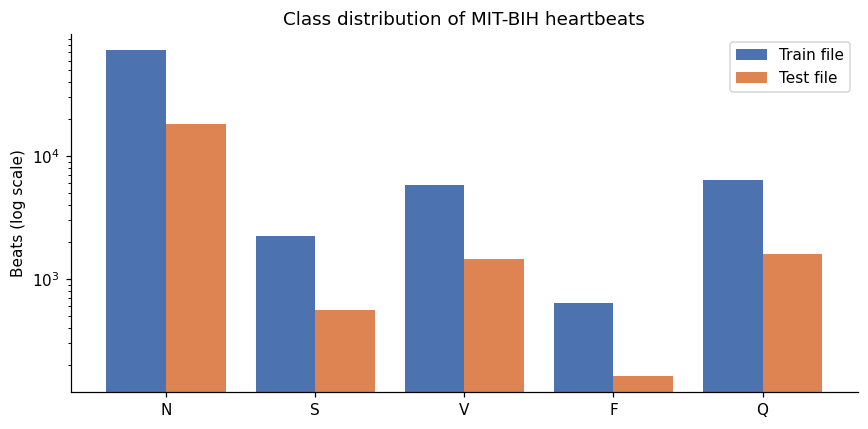

In [7]:
def class_table(df: pd.DataFrame) -> pd.DataFrame:
    counts = df["label"].value_counts().reindex(range(N_CLASSES), fill_value=0)
    return pd.DataFrame({"count": counts, "percent": (counts / counts.sum() * 100).round(2)})

dist = pd.concat({"train": class_table(train_raw), "test": class_table(test_raw)}, axis=1)
dist.index = CLASS_NAMES
display(dist)
print(f"Imbalance ratio (largest/smallest class, train): {dist[('train','count')].max() / dist[('train','count')].min():.1f} : 1")

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(N_CLASSES)
ax.bar(x - 0.2, dist[("train", "count")], 0.4, label="Train file", color='#4C72B0')
ax.bar(x + 0.2, dist[("test", "count")], 0.4, label="Test file", color='#DD8452')
ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels(SHORT)
ax.set_ylabel("Beats (log scale)")
ax.set_title("Class distribution of MIT-BIH heartbeats")
ax.legend()
plt.tight_layout()
savefig("fig01_class_distribution.png")
plt.show()

Normal beats are 82.8% of both files and fusion beats only 0.7%, an imbalance of 113 : 1. A model that
always says "normal" would get about 83% accuracy and catch nothing, so I select models on **macro-F1**, where every class
counts equally, and also track balanced accuracy and recall for S and F.

The class percentages in train and test match to two decimals. That tells me the files were split beat by beat, not
patient by patient.

### 2.3 What each class looks like

Five random beats per class, then the mean beat ± 1 standard deviation.

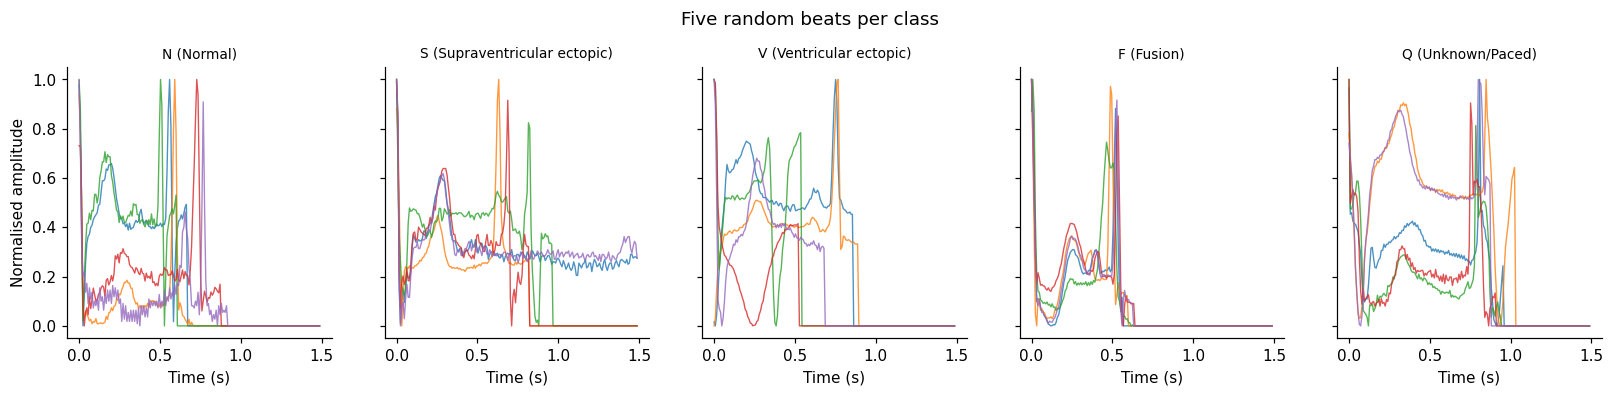

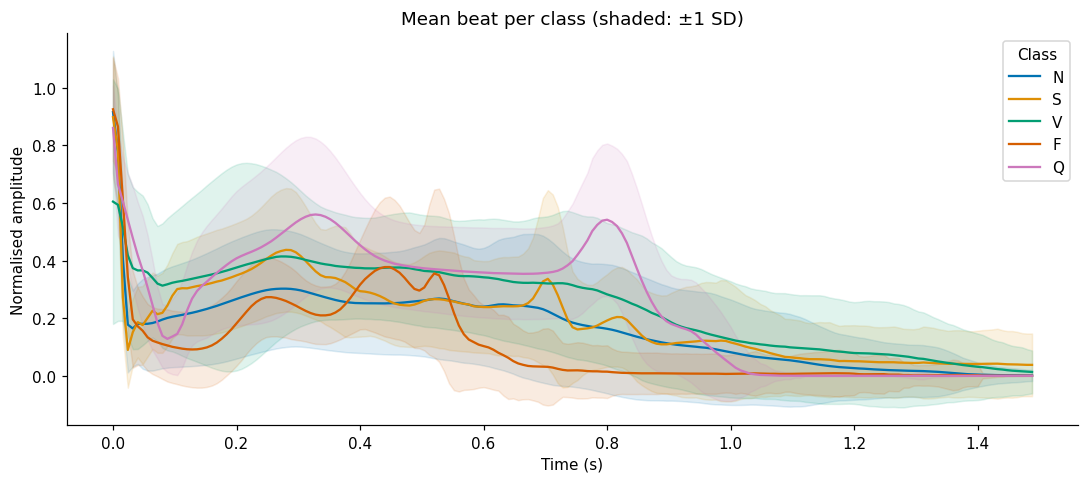

In [8]:
rng = np.random.default_rng(SEED)
t_axis = np.arange(SEQ_LEN) / FS

fig, axes = plt.subplots(1, N_CLASSES, figsize=(18, 3.2), sharey=True)
for c, ax in enumerate(axes):
    idx = rng.choice(np.where(train_raw["label"] == c)[0], size=5, replace=False)
    for i in idx:
        ax.plot(t_axis, train_raw.loc[i, SIGNAL_COLS].values, lw=0.9, alpha=0.8)
    ax.set_title(CLASS_NAMES[c], fontsize=9)
    ax.set_xlabel("Time (s)")
axes[0].set_ylabel("Normalised amplitude")
plt.suptitle("Five random beats per class", y=1.04)
savefig("fig02_example_beats.png")
plt.show()

fig, ax = plt.subplots(figsize=(10, 4.5))
for c in range(N_CLASSES):
    sig_c = train_raw.loc[train_raw["label"] == c, SIGNAL_COLS].values
    mu, sd = sig_c.mean(0), sig_c.std(0)
    ax.plot(t_axis, mu, color=PALETTE[c], label=SHORT[c])
    ax.fill_between(t_axis, mu - sd, mu + sd, color=PALETTE[c], alpha=0.12)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Normalised amplitude")
ax.legend(title="Class")
ax.set_title("Mean beat per class (shaded: ±1 SD)")
plt.tight_layout()
savefig("fig03_mean_beats.png")
plt.show()

**Interpretation.** Every class starts at the R-peak and differs in what follows. V beats tend to have a wider complex because
the impulse starts in the ventricles. S beats look close to normal in shape; what makes them abnormal is that they arrive
early, which one isolated beat barely shows. F beats are a blend of normal and ventricular. The wide bands show a lot of
variation inside each class, so some overlap between classes is unavoidable.

### 2.4 Zero padding as a heart-rate proxy

Each beat runs from its R-peak to 1.2 × the median RR interval of its 10-second window, then gets zero-padded. So the
non-padded length (`eff_len`) tells me the heart rate around the beat.

Effective beat length per class (samples) and the heart rate implied by its median


,count,mean,std,min,25%,50%,75%,max,implied_heart_rate_bpm
N (Normal),72471.0,110.8,27.2,17.0,93.0,106.0,127.0,187.0,85.0
S (Supraventricular ectopic),2223.0,113.9,39.2,22.0,95.0,107.0,135.0,187.0,84.0
V (Ventricular ectopic),5788.0,118.2,34.9,27.0,95.0,114.0,141.0,187.0,79.0
F (Fusion),641.0,78.8,13.9,29.0,74.0,78.0,81.0,187.0,115.0
Q (Unknown/Paced),6431.0,118.3,9.7,31.0,116.0,120.0,123.0,183.0,75.0


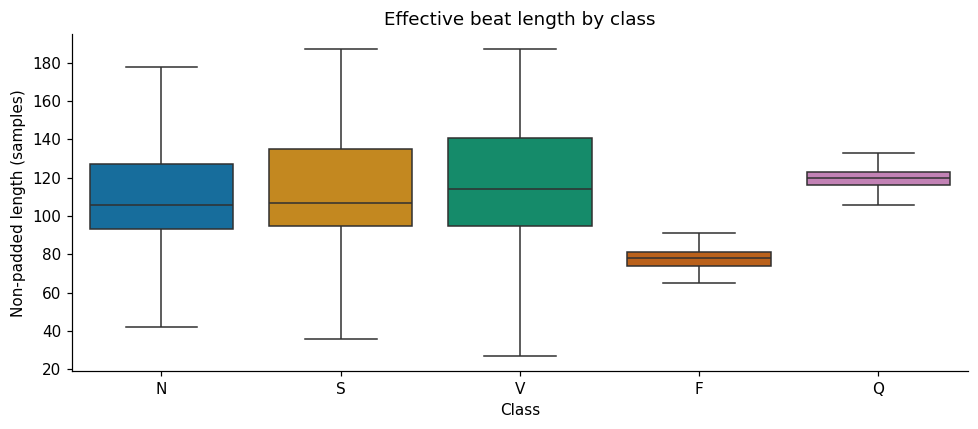

In [9]:
def effective_length(X: np.ndarray) -> np.ndarray:
    """Number of samples before the trailing zero padding."""
    nonzero = X != 0
    last = X.shape[1] - np.argmax(nonzero[:, ::-1], axis=1)
    return np.where(nonzero.any(axis=1), last, 0)

eff_df = pd.DataFrame({"label": train_raw["label"], "eff_len": effective_length(train_raw[SIGNAL_COLS].values)})
summary = eff_df.groupby("label")["eff_len"].describe().set_axis(CLASS_NAMES, axis=0)
summary["implied_heart_rate_bpm"] = (60 / ((summary["50%"] / 1.2) / FS)).round(0)
print("Effective beat length per class (samples) and the heart rate implied by its median")
display(summary.round(1))

fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=eff_df, x="label", y="eff_len", hue="label", ax=ax, showfliers=False, palette=PALETTE, legend=False)
ax.set_xticks(range(N_CLASSES))
ax.set_xticklabels(SHORT)
ax.set_xlabel("Class")
ax.set_ylabel("Non-padded length (samples)")
ax.set_title("Effective beat length by class")
plt.tight_layout()
savefig("fig04_effective_length.png")
plt.show()

F beats are much shorter (median 78 samples vs 106 for N), which means a faster surrounding heart rate,
about 115 vs 85 bpm. Q beats barely vary (SD 9.7) because a pacemaker fixes the rate. S beats are the same length as N:
the length reflects the window's average rhythm, not whether this one beat came early, so I expect S to be the hardest class.

**Shortcut risk.** F beats come mostly from two recordings (208 and 213) and paced beats from four. A heart-rate feature can
therefore partly identify *the patient* rather than the arrhythmia. Section 9 tests this.

## 3. Preprocessing and splits

1. Drop exact duplicate beats from the training file, and any training beat that also appears in the test file.
2. Hold out 15% of the training file (stratified by class) for validation. The test file is used once, in Section 8.
3. Keep a fixed 20,000-beat slice of the training split to measure training macro-F1, so the train-validation gap is
   measured the same way for every model.
4. The networks use the [0, 1] signal as it is. Engineered features have very different scales, so the traditional models
   standardise them inside a `Pipeline` fitted on training data only.
5. No outlier clipping: amplitudes are bounded, and unusual shapes are the arrhythmias themselves.
6. I handle the imbalance with class weights during training rather than throwing away normal beats.

In [10]:
n_before = len(train_raw)
train_clean = train_raw.drop_duplicates(subset=SIGNAL_COLS).copy()
n_dupes = n_before - len(train_clean)

train_fp = pd.util.hash_pandas_object(train_clean[SIGNAL_COLS], index=False)
leakage_mask = train_fp.isin(set(test_fingerprints)).values
train_clean = train_clean[~leakage_mask]
print(f"Removed {n_dupes} duplicate beats and {int(leakage_mask.sum())} train/test overlaps -> {len(train_clean):,} training beats")

Removed 0 duplicate beats and 0 train/test overlaps -> 87,554 training beats


In [11]:
X_all = train_clean[SIGNAL_COLS].values.astype("float32")
y_all = train_clean["label"].values
X_test = test_raw[SIGNAL_COLS].values.astype("float32")
y_test = test_raw["label"].values

if SMOKE_TEST:
    X_all, _, y_all, _ = train_test_split(X_all, y_all, train_size=min(3000, len(y_all) - 10),
                                          stratify=y_all, random_state=SEED)

X_train, X_val, y_train, y_val = train_test_split(X_all, y_all, test_size=0.15, stratify=y_all, random_state=SEED)

# Fixed slice of the training split used to measure training-set macro-F1 for every model
_, X_tr_eval, _, y_tr_eval = train_test_split(X_train, y_train, test_size=min(20000, len(y_train) // 4),
                                              stratify=y_train, random_state=SEED)

split_table = pd.DataFrame({"train": np.bincount(y_train, minlength=N_CLASSES),
                            "validation": np.bincount(y_val, minlength=N_CLASSES),
                            "test": np.bincount(y_test, minlength=N_CLASSES)}, index=SHORT).T
split_table["total"] = split_table.sum(axis=1)
print("Dataset split matrix")
display(split_table)
SPLIT_DESC = f"train {len(y_train):,} / val {len(y_val):,} (stratified 85/15, seed {SEED})"

cw_bal = compute_class_weight("balanced", classes=np.arange(N_CLASSES), y=y_train)
CW_BALANCED = {i: float(w) for i, w in enumerate(cw_bal)}
CW_SQRT = {i: float(np.sqrt(w)) for i, w in enumerate(cw_bal)}
print("Loss penalty weights by class")
display(pd.DataFrame({"balanced": CW_BALANCED, "sqrt-dampened": CW_SQRT}).set_axis(SHORT, axis=0).round(2))

Dataset split matrix


,N,S,V,F,Q,total
train,61600,1889,4920,545,5466,74420
validation,10871,334,868,96,965,13134
test,18118,556,1448,162,1608,21892


Loss penalty weights by class


,balanced,sqrt-dampened
N,0.24,0.49
S,7.88,2.81
V,3.03,1.74
F,27.31,5.23
Q,2.72,1.65


Nothing was removed (no duplicates, no overlap), so I train on 74,420 beats, validate on 13,134 and test on
21,892, with the same class mix in each.

"Balanced" weights make an F beat count 27× a normal beat, which can make training erratic. So I also use square-root
weights (F about 5×, S about 3×), which keep the order but soften the extremes.

## 4. Feature engineering

Trees and linear models don't pick up local shape patterns from 187 raw samples as easily as a CNN does, so I give them
24 clinically motivated features, computed on the non-padded part of each beat:

| Group | Features | Why |
|---|---|---|
| Rhythm | `eff_len` | heart-rate proxy (Section 2.4) |
| Amplitude | mean, std, min, max, median, range, energy, 10/25/75/90th percentiles | overall shape |
| Slope | first-derivative statistics, position of the minimum | width and sharpness of the QRS (broad in V beats) |
| Peaks | number of peaks, position and height of the main secondary peak | P- and T-wave structure |
| Frequency | share of energy in 0-5, 5-15, 15-40, 40-62.5 Hz | QRS energy sits mostly in 5-15 Hz |
| Coarse shape | every 6th sample (32 values), only in `eng+ds` | the waveform outline without 187 correlated inputs |

I compare three input sets: **raw** (187 samples), **eng** (24 features) and **eng+ds** (56). Features are computed
separately for each split, so nothing leaks from validation or test.

In [12]:
def extract_features(X: np.ndarray, fs: int = FS) -> pd.DataFrame:
    """Hand-crafted rhythm, morphology, slope, peak and spectral features for each beat (row of X)."""
    n, L = X.shape
    nonzero = X != 0
    eff = np.maximum(L - np.argmax(nonzero[:, ::-1], axis=1), 2)
    mask = np.arange(L)[None, :] < eff[:, None]
    Xm = np.where(mask, X, np.nan)

    f = {"eff_len": eff.astype("float32")}
    mean = np.nanmean(Xm, axis=1)
    std = np.nanstd(Xm, axis=1) + 1e-8
    f.update({"mean": mean, "std": std, "min": np.nanmin(Xm, axis=1), "max": np.nanmax(Xm, axis=1),
              "median": np.nanmedian(Xm, axis=1), "energy": np.nansum(Xm ** 2, axis=1) / eff})
    f["range"] = f["max"] - f["min"]
    for q in (10, 25, 75, 90):
        f[f"q{q}"] = np.nanpercentile(Xm, q, axis=1)

    d = np.diff(Xm, axis=1)
    f.update({"d_mean_abs": np.nanmean(np.abs(d), axis=1), "d_std": np.nanstd(d, axis=1),
              "d_max": np.nanmax(d, axis=1), "d_min": np.nanmin(d, axis=1)})
    f["argmin"] = np.nanargmin(Xm, axis=1) / eff

    n_peaks, peak_pos, peak_h = np.zeros(n), np.zeros(n), np.zeros(n)
    for i in range(n):
        seg = X[i, 5:int(eff[i])]                      # skip the R-peak at the start of the window
        p, props = sps.find_peaks(seg, prominence=0.05)
        n_peaks[i] = len(p)
        if len(p):
            j = np.argmax(props["prominences"])
            peak_pos[i] = (p[j] + 5) / eff[i]
            peak_h[i] = seg[p[j]]
    f.update({"n_peaks": n_peaks, "peak2_pos": peak_pos, "peak2_height": peak_h})

    X_centered = np.where(mask, X - mean[:, None], 0)   # remove the DC component before the FFT
    spec = np.abs(np.fft.rfft(X_centered, axis=1)) ** 2
    freqs = np.fft.rfftfreq(L, 1 / fs)
    total_spec = spec.sum(axis=1) + 1e-8
    for lo, hi in [(0, 5), (5, 15), (15, 40), (40, fs / 2 + 1)]:
        f[f"band_{lo}_{int(hi)}Hz"] = spec[:, (freqs >= lo) & (freqs < hi)].sum(axis=1) / total_spec
    return pd.DataFrame(f)

def downsampled(X: np.ndarray, step: int = 6) -> pd.DataFrame:
    """Every `step`-th sample: a coarse outline of the waveform."""
    return pd.DataFrame(X[:, ::step], columns=[f"ds{i:02d}" for i in range(X[:, ::step].shape[1])])

def features_for(X: np.ndarray, name: str) -> np.ndarray:
    """Build any feature set from raw beats (also used for the inter-patient data in Section 9)."""
    if name == "raw":
        return X
    eng = extract_features(X).values
    return eng if name == "eng" else np.hstack([eng, downsampled(X).values])

t0 = time.time()
ENG = {split: extract_features(X) for split, X in
       [("train", X_train), ("val", X_val), ("test", X_test), ("tr_eval", X_tr_eval)]}
print(f"Extraction complete in {time.time() - t0:.1f}s | {ENG['train'].shape[1]} engineered features per beat")

RAW = {"train": X_train, "val": X_val, "test": X_test, "tr_eval": X_tr_eval}
def feature_set(name: str, split: str) -> np.ndarray:
    """Return feature set 'raw', 'eng' or 'eng+ds' for a split, reusing the cached engineered features."""
    if name == "raw":
        return RAW[split]
    if name == "eng":
        return ENG[split].values
    if name == "eng+ds":
        return np.hstack([ENG[split].values, downsampled(RAW[split]).values])
    raise ValueError(f"Unknown feature set: {name}")

FEATURE_NAMES = {"raw": SIGNAL_COLS, "eng": list(ENG["train"].columns),
                 "eng+ds": list(ENG["train"].columns) + list(downsampled(X_train[:1]).columns)}
display(ENG["train"].assign(label=y_train).groupby("label").mean().set_axis(SHORT, axis=0).T.round(3))

Extraction complete in 50.0s | 24 engineered features per beat


,N,S,V,F,Q
eff_len,110.819,113.966,118.392,79.114,118.237
mean,0.272,0.325,0.396,0.252,0.394
std,0.170,0.158,0.178,0.205,0.184
min,0.000,0.001,0.000,0.003,0.000
max,1.000,0.992,0.999,1.000,1.000
median,0.242,0.303,0.379,0.207,0.374
energy,0.123,0.146,0.215,0.114,0.208
range,0.999,0.991,0.999,0.997,1.000
q10,0.145,0.185,0.226,0.075,0.165
q25,0.193,0.265,0.326,0.127,0.333


### 4.1 Feature importance

A quick Random Forest ranks the engineered features by mean decrease in impurity. It's a rough guide: it can favour
features with many distinct values and splits credit between correlated ones.

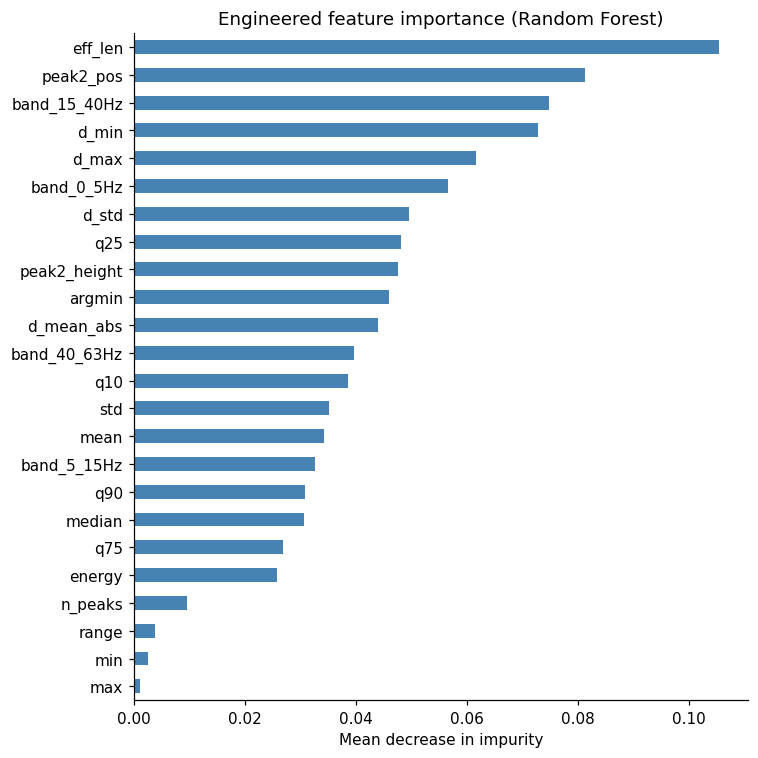

Top 5 features: ['eff_len', 'peak2_pos', 'band_15_40Hz', 'd_min', 'd_max']


In [13]:
fs_rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED, class_weight="balanced_subsample")
fs_rf.fit(feature_set("eng", "train"), y_train)
imp = pd.Series(fs_rf.feature_importances_, index=FEATURE_NAMES["eng"]).sort_values()

fig, ax = plt.subplots(figsize=(7, 7))
imp.plot.barh(ax=ax, color="steelblue")
ax.set_xlabel("Mean decrease in impurity")
ax.set_title("Engineered feature importance (Random Forest)")
plt.tight_layout()
savefig("fig05_feature_importance.png")
plt.show()
print("Top 5 features:", list(imp.index[::-1][:5]))

The top five are `eff_len`, `peak2_pos`, `band_15_40Hz`, `d_min` and `d_max`. Beat length ranks first,
which confirms rhythm matters, but given Section 2.4 some of that may be patient recognition. `peak2_pos` (where the T wave
or next beat falls) and the slope extremes describe the width and sharpness of the QRS, which is how cardiologists tell V
beats apart. No feature is near zero, so I keep all 24.

## 5. Traditional ML experiments

### 5.1 Logging framework

Every experiment, traditional or deep, is scored by the same function and appended to one log, `RESULTS_LOG`, which becomes
the experiment table in Section 7. Nothing in that table is typed by hand.

Metrics: macro-F1 (the selection metric), balanced accuracy, macro ROC-AUC, accuracy, recall per class, training macro-F1 on
the fixed slice, and the **F1 gap** (train minus validation) as a sign of overfitting.

In [14]:
RESULTS_LOG = []
FITTED_ML_MODELS = {}

def evaluate_predictions(y_true: np.ndarray, proba: np.ndarray) -> dict:
    """Macro-F1, balanced accuracy, macro ROC-AUC, accuracy and per-class recall from class probabilities."""
    pred = proba.argmax(axis=1)
    rec = recall_score(y_true, pred, labels=range(N_CLASSES), average=None, zero_division=0)
    try:
        auc_macro = roc_auc_score(y_true, proba, multi_class="ovr", average="macro", labels=range(N_CLASSES))
    except ValueError:
        auc_macro = np.nan
    metrics = {"accuracy": accuracy_score(y_true, pred), "balanced_acc": balanced_accuracy_score(y_true, pred),
               "macro_f1": f1_score(y_true, pred, average="macro", zero_division=0), "macro_auc": auc_macro}
    for idx, name in enumerate(SHORT):
        metrics[f"recall_{name}"] = rec[idx]
    return metrics

def stratified_subsample(X: np.ndarray, y: np.ndarray, n: int):
    """Stratified random subset of n rows (returns the input unchanged if n >= len(y))."""
    if n >= len(y):
        return X, y
    Xs, _, ys, _ = train_test_split(X, y, train_size=n, stratify=y, random_state=SEED)
    return Xs, ys

def log_result(exp_id, paradigm, model_name, input_desc, hyperparams, val_m, train_f1, train_time, notes=""):
    row = {"exp_id": exp_id, "paradigm": paradigm, "model": model_name, "input": input_desc,
           "hyperparameters": hyperparams, "split": SPLIT_DESC,
           "train_macro_f1": train_f1, "val_macro_f1": val_m["macro_f1"], "f1_gap": train_f1 - val_m["macro_f1"],
           "val_balanced_acc": val_m["balanced_acc"], "val_macro_auc": val_m["macro_auc"], "val_accuracy": val_m["accuracy"],
           **{f"val_recall_{s}": val_m[f"recall_{s}"] for s in SHORT},
           "train_time_s": train_time, "notes": notes}
    RESULTS_LOG[:] = [r for r in RESULTS_LOG if r["exp_id"] != exp_id]   # re-running a cell replaces, never duplicates
    RESULTS_LOG.append(row)
    print(f"{exp_id:<6}| {model_name:<32}| val F1 {val_m['macro_f1']:.4f} | bal-acc {val_m['balanced_acc']:.4f} | "
          f"recall S {val_m['recall_S']:.3f} F {val_m['recall_F']:.3f} | train F1 {train_f1:.4f} | {train_time:.1f}s")

def run_ml_experiment(exp_id: str, model_name: str, estimator_instance, feature_set_name: str,
                      hyperparams_notes: str, notes: str = "", subsample: int = None):
    """Fit StandardScaler + estimator on the training split (optionally a stratified subsample) and log the run."""
    set_seeds()
    X_tr, y_tr = feature_set(feature_set_name, "train"), y_train
    if subsample:
        X_tr, y_tr = stratified_subsample(X_tr, y_tr, subsample)
    pipe = Pipeline([("scaler", StandardScaler()), ("clf", estimator_instance)])
    start = time.time()
    pipe.fit(X_tr, y_tr)
    train_time = time.time() - start

    val_metrics = evaluate_predictions(y_val, pipe.predict_proba(feature_set(feature_set_name, "val")))
    train_f1 = f1_score(y_tr_eval, pipe.predict(feature_set(feature_set_name, "tr_eval")), average="macro", zero_division=0)
    input_desc = f"{feature_set_name} ({X_tr.shape[1]} feats, {len(y_tr):,} rows{' subsample' if subsample else ''})"
    log_result(exp_id, "Traditional ML", model_name, input_desc, hyperparams_notes, val_metrics, train_f1, train_time, notes)
    FITTED_ML_MODELS[exp_id] = {"model": pipe, "feature_set": feature_set_name}
    return pipe

print("Experiment framework ready.")

Experiment framework ready.


### 5.2 Experiment design

Each run changes one thing from a named earlier run, so I can tell what caused each difference.

| ID | Model and input | Change vs | Question |
|---|---|---|---|
| ML-1 | Logistic Regression, raw, unweighted | (baseline) | How far does a straight-line boundary on raw samples get? |
| ML-2A | Logistic Regression, eng+ds, unweighted | ML-1: features | Do engineered features help a linear model? |
| ML-2B | Logistic Regression, eng+ds, balanced | ML-2A: weighting | What does class weighting trade off? |
| ML-3A | Random Forest, raw, balanced | (non-linear baseline) | Do non-linear splits help on raw input? |
| ML-3B | Random Forest, eng+ds, balanced | ML-3A: features | Do engineered features help a tree ensemble? |
| ML-4 | Hist Gradient Boosting, eng+ds, defaults | ML-3B: bagging → boosting | Does sequential error correction beat averaging? |
| ML-5 | ML-4 tuned with search A | ML-4: tuning | How much does tuning add? |
| ML-6 | ML-4 tuned with search B (wider) | ML-5: search space | Does a wider search help further? |
| ML-7 | RBF SVM, eng+ds, 15k sample | (different family) | Kernel method: accuracy vs training cost |

In [15]:
run_ml_experiment("ML-1", "Logistic Regression", LogisticRegression(max_iter=1000, random_state=SEED),
                  "raw", "C=1.0, lbfgs, max_iter=1000, unweighted", "Linear baseline on raw samples")

run_ml_experiment("ML-2A", "Logistic Regression", LogisticRegression(max_iter=1000, random_state=SEED),
                  "eng+ds", "C=1.0, lbfgs, max_iter=1000, unweighted", "Isolates engineered features (linear)")

run_ml_experiment("ML-2B", "Logistic Regression", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED),
                  "eng+ds", "C=1.0, lbfgs, max_iter=1000, class_weight=balanced", "Isolates class weighting (linear)")

run_ml_experiment("ML-3A", "Random Forest",
                  RandomForestClassifier(n_estimators=100, max_depth=12, n_jobs=-1, random_state=SEED, class_weight="balanced"),
                  "raw", "n_estimators=100, max_depth=12, class_weight=balanced", "Non-linear model on raw samples")

run_ml_experiment("ML-3B", "Random Forest",
                  RandomForestClassifier(n_estimators=100, max_depth=12, n_jobs=-1, random_state=SEED, class_weight="balanced"),
                  "eng+ds", "n_estimators=100, max_depth=12, class_weight=balanced", "Isolates engineered features (trees)")

run_ml_experiment("ML-4", "Hist Gradient Boosting", HistGradientBoostingClassifier(random_state=SEED),
                  "eng+ds", "learning_rate=0.1, max_iter=100, max_leaf_nodes=31 (defaults)", "Boosting vs bagging")

ML-1  | Logistic Regression             | val F1 0.6717 | bal-acc 0.6038 | recall S 0.473 F 0.323 | train F1 0.6626 | 61.1s
ML-2A | Logistic Regression             | val F1 0.7169 | bal-acc 0.6583 | recall S 0.329 F 0.323 | train F1 0.7205 | 13.6s
ML-2B | Logistic Regression             | val F1 0.5594 | bal-acc 0.8349 | recall S 0.746 F 0.875 | train F1 0.5579 | 19.6s
ML-3A | Random Forest                   | val F1 0.8219 | bal-acc 0.8679 | recall S 0.713 F 0.781 | train F1 0.8917 | 26.3s
ML-3B | Random Forest                   | val F1 0.8512 | bal-acc 0.8789 | recall S 0.695 F 0.812 | train F1 0.9244 | 15.7s
ML-4  | Hist Gradient Boosting          | val F1 0.9011 | bal-acc 0.8677 | recall S 0.746 F 0.677 | train F1 0.9895 | 8.9s


Pipeline(steps=[('scaler', StandardScaler()),
                ('clf', HistGradientBoostingClassifier(random_state=42))])

From ML-1 to ML-4:

- **Features help a linear model (ML-1 → ML-2A, +0.045).** On raw samples, logistic regression has to weight each time
  position, so a slightly shifted beat looks different. The features describe the shape instead.
- **Class weights trade precision for recall (ML-2A → ML-2B).** Macro-F1 fell by 0.158, but balanced accuracy rose by 0.177
  and F recall went from 0.32 to 0.88. The model calls rare classes much more often, so it catches more of them but raises
  many false alarms.
- **Trees beat straight lines (ML-2A → ML-3A, +0.105).** Trees combine thresholds into non-linear rules, and S and F recall
  roughly doubled.
- **Features help trees too (ML-3A → ML-3B, +0.029),** and the forest trained faster on 56 inputs than on 187.
- **Boosting beats bagging (ML-3B → ML-4, +0.050).** Each new tree corrects the previous trees' mistakes, instead of
  averaging independent trees.

### 5.3 ML-5 and ML-6: hyperparameter search

Both searches use `RandomizedSearchCV`: they try random combinations from a menu of settings, score each with stratified
3-fold cross-validation on the training split only, and refit the best one.

- **Search A (ML-5)** tries 6 of the 81 combinations of learning rate, number of trees (`max_iter`), leaves per tree and
  minimum beats per leaf.
- **Search B (ML-6)** tries 12 combinations from a much wider menu that also includes L2 regularisation, class weights and
  early stopping.

In [16]:
def run_search(exp_id, param_space, n_iter, base_estimator, notes):
    """Randomised 3-fold CV search on the training split, then refit + log the best configuration."""
    set_seeds()
    search = RandomizedSearchCV(Pipeline([("scaler", StandardScaler()), ("clf", base_estimator)]),
                                param_space, n_iter=n_iter, scoring="f1_macro", random_state=SEED, n_jobs=-1,
                                cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED))
    start = time.time()
    search.fit(feature_set("eng+ds", "train"), y_train)
    duration = time.time() - start
    print(f"[{exp_id}] search: {n_iter} candidates x 3 folds in {duration:.1f}s | best CV macro-F1 {search.best_score_:.4f}")

    res = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
    res.to_csv(os.path.join(DIRS["results"], f"{exp_id}_search_results.csv"), index=False)
    display(res[[c for c in res.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score"]].head(6))

    best = {k.replace("clf__", ""): v for k, v in search.best_params_.items()}
    estimator = clone(base_estimator).set_params(**best)
    return run_ml_experiment(exp_id, "Hist Gradient Boosting (tuned)", estimator, "eng+ds",
                             ", ".join(f"{k}={v}" for k, v in best.items()),
                             f"{notes}; search {duration:.0f}s, best CV F1 {search.best_score_:.4f}")

run_search("ML-5",
           {"clf__learning_rate": [0.05, 0.1, 0.2], "clf__max_iter": [100, 200, 300],
            "clf__max_leaf_nodes": [15, 31, 63], "clf__min_samples_leaf": [20, 50, 100]},
           SEARCH_ITERS_A, HistGradientBoostingClassifier(random_state=SEED), "Search A (small grid)")

run_search("ML-6",
           {"clf__learning_rate": [0.03, 0.05, 0.1, 0.2], "clf__max_iter": [200, 400, 600],
            "clf__max_leaf_nodes": [15, 31, 63, 127], "clf__min_samples_leaf": [10, 20, 50],
            "clf__l2_regularization": [0.0, 0.1, 1.0], "clf__class_weight": [None, "balanced"]},
           SEARCH_ITERS_B, HistGradientBoostingClassifier(early_stopping=True, random_state=SEED),
           "Search B (wider space, early stopping)")

[ML-5] search: 6 candidates x 3 folds in 126.1s | best CV macro-F1 0.9028


,param_clf__min_samples_leaf,param_clf__max_leaf_nodes,param_clf__max_iter,param_clf__learning_rate,mean_test_score,std_test_score
2,50,31,300,0.05,0.902766,0.004906
3,50,31,100,0.10,0.900533,0.003459
4,20,15,300,0.05,0.899583,0.005370
0,20,31,100,0.10,0.891025,0.006543
5,50,15,100,0.10,0.890009,0.005141
1,20,15,100,0.05,0.880613,0.003724


ML-5  | Hist Gradient Boosting (tuned)  | val F1 0.9177 | bal-acc 0.8833 | recall S 0.749 F 0.750 | train F1 0.9923 | 21.0s
[ML-6] search: 12 candidates x 3 folds in 356.0s | best CV macro-F1 0.9045


,param_clf__min_samples_leaf,param_clf__max_leaf_nodes,param_clf__max_iter,param_clf__learning_rate,param_clf__l2_regularization,param_clf__class_weight,mean_test_score,std_test_score
5,50,127,200,0.03,1.0,None,0.904486,0.003183
7,20,127,200,0.03,1.0,None,0.904163,0.000853
4,50,127,400,0.03,0.0,None,0.902918,0.005448
3,10,127,400,0.03,1.0,None,0.902089,0.001649
0,10,63,400,0.05,0.1,None,0.898860,0.007532
10,10,127,600,0.10,1.0,None,0.895059,0.004323


ML-6  | Hist Gradient Boosting (tuned)  | val F1 0.9097 | bal-acc 0.8723 | recall S 0.743 F 0.698 | train F1 0.9925 | 33.8s


Pipeline(steps=[('scaler', StandardScaler()),
                ('clf',
                 HistGradientBoostingClassifier(early_stopping=True,
                                                l2_regularization=1.0,
                                                learning_rate=0.03,
                                                max_iter=200,
                                                max_leaf_nodes=127,
                                                min_samples_leaf=50,
                                                random_state=42))])

### 5.4 ML-7: RBF SVM

An RBF SVM classifies a beat by how similar it is to the borderline training beats (the support vectors), which lets it draw
curved boundaries. Training cost grows roughly with the square of the number of beats, so I train it on a stratified
15,000-beat sample and still validate on the full validation set.

In [17]:
run_ml_experiment("ML-7", "SVM (RBF kernel)",
                  SVC(C=10, kernel="rbf", gamma="scale", class_weight="balanced", probability=True, random_state=SEED),
                  "eng+ds", "C=10, gamma=scale, class_weight=balanced, probability=True",
                  f"Stratified subsample of {SVM_SUBSAMPLE:,} rows (cost ~ O(n^2))", subsample=SVM_SUBSAMPLE)

ML-7  | SVM (RBF kernel)                | val F1 0.8531 | bal-acc 0.8174 | recall S 0.590 F 0.615 | train F1 0.8269 | 24.8s


Pipeline(steps=[('scaler', StandardScaler()),
                ('clf',
                 SVC(C=10, class_weight='balanced', probability=True,
                     random_state=42))])

ML-5 to ML-7:

- **Tuning helped (ML-4 → ML-5, +0.017, to 0.918).** The winner was `learning_rate=0.05, max_iter=300, max_leaf_nodes=31,
  min_samples_leaf=50`. The search table isolates single settings: 300 trees beat 100 (0.900 vs 0.881), at least 50 beats
  per leaf beat 20 (0.901 vs 0.891), and 31 leaves beat 15 (0.901 vs 0.890). Small careful steps, moderately detailed trees
  and well-supported rules.
- **The wider search didn't (ML-5 → ML-6, −0.008).** Its CV lead was only 0.002, smaller than the spread between folds, and
  it picked large 127-leaf trees that fit training quirks. No `class_weight="balanced"` setting reached its top six.
- **The SVM scored 0.853.** It saw a fifth of the data, including only about 110 F beats, so this is an accuracy-vs-cost
  trade-off rather than a fair head-to-head. Its training F1 (0.827) was measured on the shared training slice, most of
  which the SVM never trained on, so its negative gap isn't meaningful.

### 5.5 Learning curve of ML-5

Training and cross-validation macro-F1 as the training set grows. I use a 40,000-beat sample for speed, so each fold trains
on about 27,000 beats.

Best traditional model on validation macro-F1: ML-5


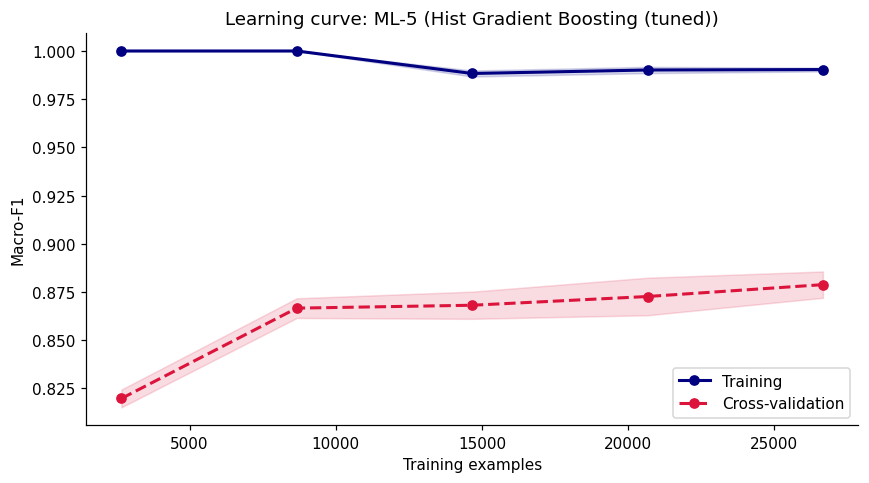

Final gap (train - CV): 0.1116 | CV gain over the last step: +0.0062


In [18]:
ml_results_df = pd.DataFrame([r for r in RESULTS_LOG if r["paradigm"] == "Traditional ML"])
BEST_ML_ID = ml_results_df.loc[ml_results_df["val_macro_f1"].idxmax(), "exp_id"]
best_ml_record = FITTED_ML_MODELS[BEST_ML_ID]
print(f"Best traditional model on validation macro-F1: {BEST_ML_ID}")

X_lc, y_lc = stratified_subsample(feature_set(best_ml_record["feature_set"], "train"), y_train,
                                  3000 if SMOKE_TEST else 40000)
train_sizes, train_scores, cv_scores = learning_curve(
    clone(best_ml_record["model"]), X_lc, y_lc, train_sizes=np.linspace(0.1, 1.0, 5),
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED), scoring="f1_macro",
    n_jobs=-1, shuffle=True, random_state=SEED)

fig, ax = plt.subplots(figsize=(8, 4.5))
for scores, label, color, style in [(train_scores, "Training", "navy", "-"), (cv_scores, "Cross-validation", "crimson", "--")]:
    ax.plot(train_sizes, scores.mean(axis=1), "o", ls=style, color=color, lw=2, label=label)
    ax.fill_between(train_sizes, scores.mean(axis=1) - scores.std(axis=1), scores.mean(axis=1) + scores.std(axis=1),
                    color=color, alpha=0.15)
ax.set_xlabel("Training examples")
ax.set_ylabel("Macro-F1")
ax.set_title(f"Learning curve: {BEST_ML_ID} ({ml_results_df.set_index('exp_id').loc[BEST_ML_ID, 'model']})")
ax.legend(loc="lower right")
plt.tight_layout()
savefig("fig06_learning_curve_best_ml.png")
plt.show()
print(f"Final gap (train - CV): {train_scores.mean(1)[-1] - cv_scores.mean(1)[-1]:.4f} | "
      f"CV gain over the last step: {cv_scores.mean(1)[-1] - cv_scores.mean(1)[-2]:+.4f}")

**Diagnosis.** Training F1 stays at 0.99-1.00 at every size, while cross-validation climbs from 0.82 to 0.88 and ends
0.11 lower. That's high variance: boosting fits its training beats far better than new ones. The CV curve is still rising at
the right edge, so more data would help, especially more S and F beats. The full ML-5, trained on 74,420 beats, reached
0.918, which fits that reading.

## 6. Deep learning with `tf.data`

### 6.1 Input pipeline

Each split becomes a `tf.data.Dataset`: shuffle (training only) → optional augmentation with `map` → batch → `prefetch`, so
the GPU never waits for data.

Augmentation (DL-7 only) imitates recording variation: ±10% amplitude scaling, small Gaussian noise (σ = 0.01) and a shift
of up to 5 samples (40 ms).

In [19]:
AUTOTUNE = tf.data.AUTOTUNE

def augment(x, y):
    scale = tf.random.uniform([], 0.9, 1.1)
    noise = tf.random.normal(tf.shape(x), stddev=0.01)
    shift = tf.random.uniform([], -5, 6, dtype=tf.int32)
    return tf.roll(x * scale + noise, shift=shift, axis=0), y

def make_dataset(X: np.ndarray, y: np.ndarray, batch_size: int = BATCH_SIZE, shuffle: bool = False,
                 use_augment: bool = False) -> tf.data.Dataset:
    """(N, 187) arrays -> batched, prefetched dataset of shape (batch, 187, 1) for Conv1D layers."""
    ds = tf.data.Dataset.from_tensor_slices((X[..., None].astype(np.float32), y.astype(np.int32)))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(X), seed=SEED, reshuffle_each_iteration=True)
        if use_augment:
            ds = ds.map(augment, num_parallel_calls=AUTOTUNE)
    return ds.batch(batch_size).prefetch(buffer_size=AUTOTUNE)

val_ds = make_dataset(X_val, y_val, batch_size=1024)
tr_eval_ds = make_dataset(X_tr_eval, y_tr_eval, batch_size=1024)
xb, yb = next(iter(make_dataset(X_train, y_train, shuffle=True, use_augment=True)))
print("Training batch:", xb.shape, xb.dtype, "| labels:", yb.shape, yb.dtype)

I0000 00:00:1792270889.847666      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792270889.852900      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Training batch: (256, 187, 1) <dtype: 'float32'> | labels: (256,) <dtype: 'int32'>


### 6.2 Architectures

All four are built with the Keras Functional API and end in the same head: Dense → Dropout → Dense(5, softmax, float32).

| Builder | Architecture | Why |
|---|---|---|
| `build_mlp` | Flatten → Dense(256) → head | Baseline: sees every position, no notion of local shape |
| `build_cnn` | Conv1D blocks (optional 2 convs per block, BatchNorm, spatial dropout) → global average pooling → head | Filters learn local wave patterns wherever they occur |
| `build_resnet` | 5 residual Conv1D blocks (after Kachuee et al., 2018) | Skip connections let a deeper network train |
| `build_cnn_lstm` | Conv1D feature extractor → bidirectional LSTM → head | Convolutions find local shape; the LSTM reads their order |

In [20]:
def build_softmax_output(x, dense_nodes: int, dropout_rate: float):
    """Shared classification head; the softmax is forced to float32 for mixed-precision stability."""
    x = layers.Dense(dense_nodes, activation="relu")(x)
    x = layers.Dropout(dropout_rate)(x)
    return layers.Dense(N_CLASSES, activation="softmax", dtype="float32", name="softmax_probs")(x)

def build_mlp(units=256, head=128, dropout=0.3):
    inputs = keras.Input(shape=(SEQ_LEN, 1))
    x = layers.Dropout(dropout)(layers.Dense(units, activation="relu")(layers.Flatten()(inputs)))
    return keras.Model(inputs, build_softmax_output(x, head, dropout), name="mlp")

def build_cnn(filters=(32, 64), kernel=5, convs_per_block=1, batchnorm=False, dropout=0.3, head=64):
    inputs = keras.Input(shape=(SEQ_LEN, 1))
    x = inputs
    for f in filters:
        for _ in range(convs_per_block):
            x = layers.Conv1D(f, kernel, padding="same", use_bias=not batchnorm)(x)
            if batchnorm:
                x = layers.BatchNormalization()(x)
            x = layers.ReLU()(x)
        x = layers.MaxPooling1D(2)(x)
        if batchnorm:
            x = layers.SpatialDropout1D(dropout / 2)(x)
    x = layers.GlobalAveragePooling1D()(x)
    return keras.Model(inputs, build_softmax_output(x, head, dropout), name="cnn")

def build_resnet(n_blocks=5, filters=32, kernel=5, dropout=0.3, head=64):
    inputs = keras.Input(shape=(SEQ_LEN, 1))
    x = layers.Conv1D(filters, kernel, padding="same")(inputs)
    for _ in range(n_blocks):
        h = layers.Conv1D(filters, kernel, padding="same", activation="relu")(x)
        h = layers.Conv1D(filters, kernel, padding="same")(h)
        x = layers.ReLU()(layers.Add()([x, h]))
        x = layers.MaxPooling1D(5, strides=2, padding="same")(x)
    x = layers.Flatten()(x)
    return keras.Model(inputs, build_softmax_output(x, head, dropout), name="resnet")

def build_cnn_lstm(filters=(32, 64), kernel=5, lstm_units=64, dropout=0.3, head=64):
    inputs = keras.Input(shape=(SEQ_LEN, 1))
    x = inputs
    for f in filters:
        x = layers.MaxPooling1D(2)(layers.Conv1D(f, kernel, padding="same", activation="relu")(x))
    x = layers.Bidirectional(layers.LSTM(lstm_units))(x)
    return keras.Model(inputs, build_softmax_output(x, head, dropout), name="cnn_bilstm")

BUILDERS = {"mlp": build_mlp, "cnn": build_cnn, "resnet": build_resnet, "cnn_lstm": build_cnn_lstm}
for name, builder in BUILDERS.items():
    print(f"{name:<9} parameters: {builder().count_params():>9,}")
keras.backend.clear_session()

mlp       parameters:    81,669
cnn       parameters:    14,981
resnet    parameters:    64,389
cnn_lstm  parameters:    85,125


### 6.3 Training setup

One function trains, scores, logs and saves every network, so all eight runs follow the same rules:

- Adam, sparse categorical cross-entropy, up to 40 epochs.
- A callback computes validation macro-F1 after each epoch, and **early stopping watches macro-F1** (patience 6, best
  weights restored). Validation loss is dominated by normal beats, so it can improve while S and F get worse.
- `ReduceLROnPlateau` halves the learning rate when validation loss stalls for 3 epochs.
- Every run writes a TensorBoard folder and a CSV log.

In [21]:
class MacroF1Callback(keras.callbacks.Callback):
    """Adds val_macro_f1 to the epoch logs so EarlyStopping, TensorBoard and CSVLogger all see it."""
    def __init__(self, val_dataset, y_true):
        super().__init__()
        self.val_dataset, self.y_true = val_dataset, y_true
    def on_epoch_end(self, epoch, logs=None):
        logs = logs if logs is not None else {}
        pred = self.model.predict(self.val_dataset, verbose=0).argmax(axis=1)
        logs["val_macro_f1"] = f1_score(self.y_true, pred, average="macro", zero_division=0)

DL_HISTORY, DL_CONFIG, DL_MODEL_PATHS = {}, {}, {}

def make_callbacks(exp_id, val_dataset, y_val_true, csv=True):
    run_dir = os.path.join(DIRS["logs"], exp_id)
    shutil.rmtree(run_dir, ignore_errors=True)
    cbs = [MacroF1Callback(val_dataset, y_val_true),          # must be first so the others see val_macro_f1
           keras.callbacks.EarlyStopping(monitor="val_macro_f1", mode="max", patience=6, restore_best_weights=True),
           keras.callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min", factor=0.5, patience=3, min_lr=1e-5),
           keras.callbacks.TensorBoard(log_dir=run_dir)]
    if csv:
        cbs.append(keras.callbacks.CSVLogger(os.path.join(DIRS["logs"], f"{exp_id}.csv")))
    return cbs

def run_dl_experiment(exp_id, model_name, arch, arch_kwargs, lr=1e-3, batch_size=BATCH_SIZE,
                      class_weight=None, cw_name="none", use_augment=False, notes=""):
    """Build, train, evaluate, log and save one network."""
    keras.backend.clear_session()
    set_seeds()
    model = BUILDERS[arch](**arch_kwargs)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="sparse_categorical_crossentropy")
    train_ds = make_dataset(X_train, y_train, batch_size, shuffle=True, use_augment=use_augment)

    start = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=MAX_EPOCHS, class_weight=class_weight,
                     callbacks=make_callbacks(exp_id, val_ds, y_val), verbose=0)
    train_time = time.time() - start

    val_metrics = evaluate_predictions(y_val, model.predict(val_ds, verbose=0))
    train_f1 = f1_score(y_tr_eval, model.predict(tr_eval_ds, verbose=0).argmax(axis=1), average="macro", zero_division=0)
    path = os.path.join(DIRS["models"], f"{exp_id}.keras")
    model.save(path)

    epochs_run = len(hist.history["loss"])
    best_epoch = int(np.argmax(hist.history["val_macro_f1"])) + 1
    hp = (", ".join(f"{k}={v}" for k, v in arch_kwargs.items()) +
          f"; Adam lr={lr}; batch={batch_size}; class_weight={cw_name}; augment={use_augment}; "
          f"epochs run={epochs_run} (best {best_epoch}); params={model.count_params():,}")
    log_result(exp_id, "Deep Learning", model_name, "raw beat (187x1) via tf.data", hp, val_metrics, train_f1, train_time, notes)
    DL_HISTORY[exp_id] = hist.history
    DL_CONFIG[exp_id] = dict(arch=arch, arch_kwargs=arch_kwargs, lr=lr, batch_size=batch_size,
                             class_weight=class_weight, cw_name=cw_name, use_augment=use_augment)
    DL_MODEL_PATHS[exp_id] = path
    return model

print("Deep-learning framework ready.")

Deep-learning framework ready.


### 6.4 Experiment design

Each run changes one thing. From DL-3 on, every run uses the square-root class weights.

| ID | Model | Change vs | Question |
|---|---|---|---|
| DL-1 | MLP | (baseline) | How well does a network do without convolution? |
| DL-2 | CNN, 2 blocks × 1 conv | DL-1: convolution | Does local pattern learning beat the MLP? |
| DL-3 | DL-2 + class weights | DL-2: weighting | Do weights raise S/F recall, and at what cost? |
| DL-4 | CNN, 3 blocks × 2 convs + BatchNorm + dropout | DL-3: capacity | Does a bigger, regularised network help? |
| DL-5 | DL-4 with learning rate 1e-2 | DL-4: learning rate | What does a 10× larger step do? |
| DL-6 | Residual CNN (5 blocks) | DL-4: skip connections | Do skip connections help a deeper network? |
| DL-7 | DL-6 + augmentation | DL-6: augmentation | Does augmentation reduce overfitting? |
| DL-8 | CNN + bidirectional LSTM | DL-4: sequence model | Does reading the beat in order add anything? |

In [22]:
run_dl_experiment("DL-1", "MLP", "mlp", dict(units=256, head=128, dropout=0.3), notes="No-convolution baseline")
run_dl_experiment("DL-2", "CNN (2 blocks)", "cnn", dict(filters=(32, 64), kernel=5), notes="Adds convolution")
run_dl_experiment("DL-3", "CNN (2 blocks) + weights", "cnn", dict(filters=(32, 64), kernel=5),
                  class_weight=CW_SQRT, cw_name="sqrt-balanced", notes="Adds class weights")

DL-1  | MLP                             | val F1 0.9010 | bal-acc 0.8610 | recall S 0.683 F 0.719 | train F1 0.9115 | 58.5s
DL-2  | CNN (2 blocks)                  | val F1 0.7076 | bal-acc 0.6676 | recall S 0.374 F 0.125 | train F1 0.7124 | 88.6s
DL-3  | CNN (2 blocks) + weights        | val F1 0.7472 | bal-acc 0.8134 | recall S 0.578 F 0.740 | train F1 0.7379 | 75.7s


<Functional name=cnn, built=True>

DL-1 to DL-3:

- **The MLP was strong (0.901).** It sees all 187 positions at once, including where the beat ends, which is the heart-rate
  cue.
- **The small CNN underfit badly (DL-1 → DL-2, −0.193).** Train and validation F1 were both about 0.71, and its best epoch
  was the last one, so it was still learning when training stopped. Each filter only sees about 16 samples (0.13 s), too
  short to relate the spike to the T wave or the beat's length, and global average pooling then throws away where things
  happen. F recall fell to 0.125.
- **Class weights changed priorities, not ability (DL-2 → DL-3).** F recall jumped from 0.125 to 0.740 and balanced accuracy
  rose 0.146, but macro-F1 only rose 0.040 and the model still underfit.

In [23]:
run_dl_experiment("DL-4", "CNN (3x2 conv) + BN", "cnn",
                  dict(filters=(32, 64, 128), kernel=5, convs_per_block=2, batchnorm=True),
                  class_weight=CW_SQRT, cw_name="sqrt-balanced", notes="Capacity + BatchNorm + dropout")
run_dl_experiment("DL-5", "CNN (3x2 conv) + BN, LR 1e-2", "cnn",
                  dict(filters=(32, 64, 128), kernel=5, convs_per_block=2, batchnorm=True), lr=1e-2,
                  class_weight=CW_SQRT, cw_name="sqrt-balanced", notes="Learning-rate sensitivity")

DL-4  | CNN (3x2 conv) + BN             | val F1 0.8762 | bal-acc 0.8833 | recall S 0.680 F 0.854 | train F1 0.8763 | 173.0s
DL-5  | CNN (3x2 conv) + BN, LR 1e-2    | val F1 0.9289 | bal-acc 0.9454 | recall S 0.916 F 0.854 | train F1 0.9598 | 615.2s


<Functional name=cnn, built=True>

DL-4 and DL-5:

- **More depth helped, but training stalled (DL-3 → DL-4, +0.129).** Six convolutions let each filter see about 64 samples
  (0.5 s), the spike and T wave together. But train and validation F1 were equal (0.876), and early stopping ended it at
  epoch 11 with its best at epoch 5. It had the capacity but wasn't learning fast enough to use it.
- **A 10× learning rate gave my best model (DL-4 → DL-5, +0.053, to 0.929).** I expected instability. Instead, the bigger
  steps got past the flat stretch where DL-4 stalled, BatchNorm kept training stable, and `ReduceLROnPlateau` shrank the
  steps as it converged. It trained all 40 epochs (best at 35) and S recall rose to 0.916. It's the same network, so the gain
  is pure optimisation, not capacity.

In [24]:
run_dl_experiment("DL-6", "Residual CNN", "resnet", dict(n_blocks=5, filters=32, kernel=5),
                  class_weight=CW_SQRT, cw_name="sqrt-balanced", notes="Skip connections")
run_dl_experiment("DL-7", "Residual CNN + augmentation", "resnet", dict(n_blocks=5, filters=32, kernel=5),
                  class_weight=CW_SQRT, cw_name="sqrt-balanced", use_augment=True, notes="Data augmentation")
run_dl_experiment("DL-8", "CNN + BiLSTM", "cnn_lstm", dict(filters=(32, 64), kernel=5, lstm_units=64),
                  class_weight=CW_SQRT, cw_name="sqrt-balanced", notes="Sequence modelling")

DL-6  | Residual CNN                    | val F1 0.9243 | bal-acc 0.9351 | recall S 0.880 F 0.833 | train F1 0.9833 | 251.1s
DL-7  | Residual CNN + augmentation     | val F1 0.9068 | bal-acc 0.9290 | recall S 0.847 F 0.854 | train F1 0.9310 | 172.7s
DL-8  | CNN + BiLSTM                    | val F1 0.8918 | bal-acc 0.9214 | recall S 0.844 F 0.833 | train F1 0.9297 | 131.4s


<Functional name=cnn_bilstm, built=True>

DL-6 to DL-8:

- **Skip connections fixed the same problem another way (DL-4 → DL-6, +0.048, to 0.924).** The ResNet trained well at the
  normal learning rate and keeps position information (it flattens instead of averaging). But training F1 reached 0.983, a
  gap of 0.059, so it started to overfit.
- **Augmentation reduced overfitting at a small cost (DL-6 → DL-7).** The gap fell from 0.059 to 0.024, but validation F1
  dropped by 0.018. My validation beats come from the same patients and are clean, so they can't show the robustness
  augmentation is meant to add.
- **The LSTM added little (DL-4 → DL-8, +0.016).** Inside a single 1.5-second beat, stacked convolutions already capture the
  order of the waves.

## 7. Experiment table, comparisons and learning curves

### 7.1 Experiment table

One row per run, saved to `results/experiment_table.csv`. This is the table I use in the report.

,exp_id,model,input,train_macro_f1,val_macro_f1,f1_gap,val_balanced_acc,val_macro_auc,val_accuracy,val_recall_S,val_recall_F,train_time_s
0,ML-1,Logistic Regression,"raw (187 feats, 74,420 rows)",0.6626,0.6717,-0.0091,0.6038,0.9250,0.9153,0.4731,0.3229,61.1
1,ML-2A,Logistic Regression,"eng+ds (56 feats, 74,420 rows)",0.7205,0.7169,0.0037,0.6583,0.9545,0.9431,0.3293,0.3229,13.6
2,ML-2B,Logistic Regression,"eng+ds (56 feats, 74,420 rows)",0.5579,0.5594,-0.0015,0.8349,0.9562,0.7533,0.7455,0.8750,19.6
3,ML-3A,Random Forest,"raw (187 feats, 74,420 rows)",0.8917,0.8219,0.0698,0.8679,0.9861,0.9658,0.7126,0.7812,26.3
4,ML-3B,Random Forest,"eng+ds (56 feats, 74,420 rows)",0.9244,0.8512,0.0732,0.8789,0.9919,0.9718,0.6946,0.8125,15.7
5,ML-4,Hist Gradient Boosting,"eng+ds (56 feats, 74,420 rows)",0.9895,0.9011,0.0884,0.8677,0.9953,0.9827,0.7455,0.6771,8.9
6,ML-5,Hist Gradient Boosting (tuned),"eng+ds (56 feats, 74,420 rows)",0.9923,0.9177,0.0746,0.8833,0.9967,0.9843,0.7485,0.7500,21.0
7,ML-6,Hist Gradient Boosting (tuned),"eng+ds (56 feats, 74,420 rows)",0.9925,0.9097,0.0828,0.8723,0.9966,0.9840,0.7425,0.6979,33.8
8,ML-7,SVM (RBF kernel),"eng+ds (56 feats, 15,000 rows subsample)",0.8269,0.8531,-0.0262,0.8174,0.9817,0.9721,0.5898,0.6146,24.8
9,DL-1,MLP,raw beat (187x1) via tf.data,0.9115,0.9010,0.0105,0.8610,0.9927,0.9809,0.6826,0.7188,58.5


,exp_id,hyperparameters,split,notes
0,ML-1,"C=1.0, lbfgs, max_iter=1000, unweighted","train 74,420 / val 13,134 (stratified 85/15, seed 42)",Linear baseline on raw samples
1,ML-2A,"C=1.0, lbfgs, max_iter=1000, unweighted","train 74,420 / val 13,134 (stratified 85/15, seed 42)",Isolates engineered features (linear)
2,ML-2B,"C=1.0, lbfgs, max_iter=1000, class_weight=balanced","train 74,420 / val 13,134 (stratified 85/15, seed 42)",Isolates class weighting (linear)
3,ML-3A,"n_estimators=100, max_depth=12, class_weight=balanced","train 74,420 / val 13,134 (stratified 85/15, seed 42)",Non-linear model on raw samples
4,ML-3B,"n_estimators=100, max_depth=12, class_weight=balanced","train 74,420 / val 13,134 (stratified 85/15, seed 42)",Isolates engineered features (trees)
5,ML-4,"learning_rate=0.1, max_iter=100, max_leaf_nodes=31 (defaults)","train 74,420 / val 13,134 (stratified 85/15, seed 42)",Boosting vs bagging
6,ML-5,"min_samples_leaf=50, max_leaf_nodes=31, max_iter=300, learning_rate=0.05","train 74,420 / val 13,134 (stratified 85/15, seed 42)","Search A (small grid); search 126s, best CV F1 0.9028"
7,ML-6,"min_samples_leaf=50, max_leaf_nodes=127, max_iter=200, learning_rate=0.03, l2_regularization=1.0, class_weight=None","train 74,420 / val 13,134 (stratified 85/15, seed 42)","Search B (wider space, early stopping); search 356s, best CV F1 0.9045"
8,ML-7,"C=10, gamma=scale, class_weight=balanced, probability=True","train 74,420 / val 13,134 (stratified 85/15, seed 42)","Stratified subsample of 15,000 rows (cost ~ O(n^2))"
9,DL-1,"units=256, head=128, dropout=0.3; Adam lr=0.001; batch=256; class_weight=none; augment=False; epochs run=33 (best 27); params=81,669","train 74,420 / val 13,134 (stratified 85/15, seed 42)",No-convolution baseline


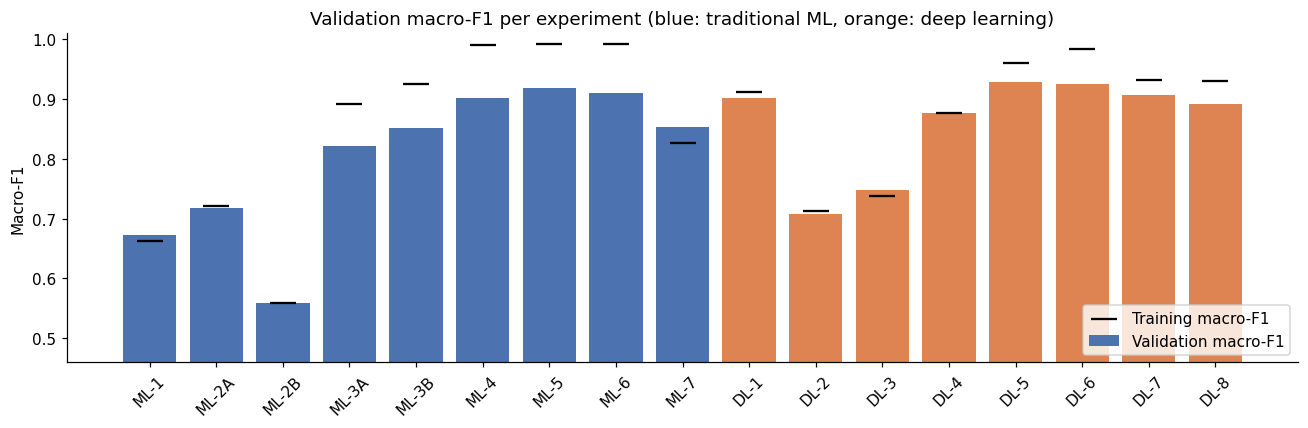

In [25]:
exp_table = pd.DataFrame(RESULTS_LOG)
exp_table.to_csv(os.path.join(DIRS["results"], "experiment_table.csv"), index=False)

show_cols = ["exp_id", "model", "input", "train_macro_f1", "val_macro_f1", "f1_gap", "val_balanced_acc", "val_macro_auc",
             "val_accuracy", "val_recall_S", "val_recall_F", "train_time_s"]
fmt = {c: "{:.4f}" for c in show_cols if exp_table[c].dtype == float}
fmt["train_time_s"] = "{:.1f}"
display(exp_table[show_cols].style.format(fmt).background_gradient(subset=["val_macro_f1"], cmap="Greens"))

with pd.option_context("display.max_colwidth", None):
    display(exp_table[["exp_id", "hyperparameters", "split", "notes"]])

fig, ax = plt.subplots(figsize=(12, 4))
colors = ["#4C72B0" if p == "Traditional ML" else "#DD8452" for p in exp_table["paradigm"]]
ax.bar(exp_table["exp_id"], exp_table["val_macro_f1"], color=colors, label="Validation macro-F1")
ax.scatter(exp_table["exp_id"], exp_table["train_macro_f1"], color="black", marker="_", s=300, label="Training macro-F1")
ax.set_ylim(max(0, exp_table["val_macro_f1"].min() - 0.1), 1.01)
ax.set_ylabel("Macro-F1")
ax.set_title("Validation macro-F1 per experiment (blue: traditional ML, orange: deep learning)")
ax.legend(loc="lower right")
plt.xticks(rotation=45)
plt.tight_layout()
savefig("fig07_experiment_comparison.png")
plt.show()

### 7.2 What each change did

For each planned comparison, the change in each metric (second run minus first). Positive Δ means the second run is better;
for the gap, positive means more overfitting.

In [26]:
PAIRS = [("ML-1", "ML-2A", "Engineered features (linear)"), ("ML-2A", "ML-2B", "Balanced class weights (linear)"),
         ("ML-2A", "ML-3A", "Linear -> Random Forest"), ("ML-3A", "ML-3B", "Engineered features (Random Forest)"),
         ("ML-3B", "ML-4", "Bagging -> boosting"), ("ML-4", "ML-5", "Tuning, search A"), ("ML-5", "ML-6", "Wider search B"),
         ("ML-4", "ML-7", "Boosting -> RBF SVM (subsample)"),
         ("DL-1", "DL-2", "Convolution vs MLP"), ("DL-2", "DL-3", "sqrt class weights"),
         ("DL-3", "DL-4", "Capacity + BatchNorm"), ("DL-4", "DL-5", "Learning rate 1e-3 -> 1e-2"),
         ("DL-4", "DL-6", "Residual connections"), ("DL-6", "DL-7", "Augmentation"), ("DL-4", "DL-8", "Add BiLSTM")]

t = exp_table.set_index("exp_id")
rows = []
for a, b, change in PAIRS:
    if a in t.index and b in t.index:
        rows.append({"from": a, "to": b, "change": change,
                     "Δ val macro-F1": t.at[b, "val_macro_f1"] - t.at[a, "val_macro_f1"],
                     "Δ balanced acc": t.at[b, "val_balanced_acc"] - t.at[a, "val_balanced_acc"],
                     "Δ recall S": t.at[b, "val_recall_S"] - t.at[a, "val_recall_S"],
                     "Δ recall F": t.at[b, "val_recall_F"] - t.at[a, "val_recall_F"],
                     "Δ F1 gap": t.at[b, "f1_gap"] - t.at[a, "f1_gap"],
                     "time ratio": t.at[b, "train_time_s"] / max(t.at[a, "train_time_s"], 1e-6)})
deltas = pd.DataFrame(rows)
deltas.to_csv(os.path.join(DIRS["results"], "experiment_deltas.csv"), index=False)
display(deltas.style.format({c: "{:+.4f}" for c in deltas.columns if c.startswith("Δ")} | {"time ratio": "{:.2f}x"})
        .background_gradient(subset=["Δ val macro-F1"], cmap="RdYlGn", vmin=-0.1, vmax=0.1))

best = t.groupby("paradigm")["val_macro_f1"].idxmax()
print("Best per paradigm:", {p: f"{e} ({t.at[e, 'val_macro_f1']:.4f})" for p, e in best.items()})
print("Largest train-val gap:", t["f1_gap"].idxmax(), f"({t['f1_gap'].max():.4f})")

,from,to,change,Δ val macro-F1,Δ balanced acc,Δ recall S,Δ recall F,Δ F1 gap,time ratio
0,ML-1,ML-2A,Engineered features (linear),+0.0452,+0.0545,-0.1437,+0.0000,+0.0128,0.22x
1,ML-2A,ML-2B,Balanced class weights (linear),-0.1575,+0.1766,+0.4162,+0.5521,-0.0051,1.44x
2,ML-2A,ML-3A,Linear -> Random Forest,+0.1050,+0.2096,+0.3832,+0.4583,+0.0661,1.93x
3,ML-3A,ML-3B,Engineered features (Random Forest),+0.0293,+0.0111,-0.0180,+0.0312,+0.0034,0.60x
4,ML-3B,ML-4,Bagging -> boosting,+0.0499,-0.0112,+0.0509,-0.1354,+0.0152,0.57x
5,ML-4,ML-5,"Tuning, search A",+0.0166,+0.0156,+0.0030,+0.0729,-0.0138,2.36x
6,ML-5,ML-6,Wider search B,-0.0080,-0.0110,-0.0060,-0.0521,+0.0082,1.60x
7,ML-4,ML-7,Boosting -> RBF SVM (subsample),-0.0480,-0.0503,-0.1557,-0.0625,-0.1145,2.78x
8,DL-1,DL-2,Convolution vs MLP,-0.1934,-0.1934,-0.3084,-0.5938,-0.0057,1.51x
9,DL-2,DL-3,sqrt class weights,+0.0396,+0.1457,+0.2036,+0.6146,-0.0141,0.85x


Best per paradigm: {'Deep Learning': 'DL-5 (0.9289)', 'Traditional ML': 'ML-5 (0.9177)'}
Largest train-val gap: ML-4 (0.0884)


**Reading the table.** The best run on each side is DL-5 (0.929) and ML-5 (0.918). The biggest gains came from moving from straight
lines to trees (+0.105) and from adding depth to the CNN (+0.129). The biggest drops came from class-weighting the linear
model (−0.158) and from the tiny CNN (−0.193). ML-4 has the largest train-validation gap (0.088), so plain boosting overfits
the most.

### 7.3 Deep-learning learning curves

Training vs validation loss (top) and validation macro-F1 (bottom) per epoch. The dashed line is the epoch early stopping kept.

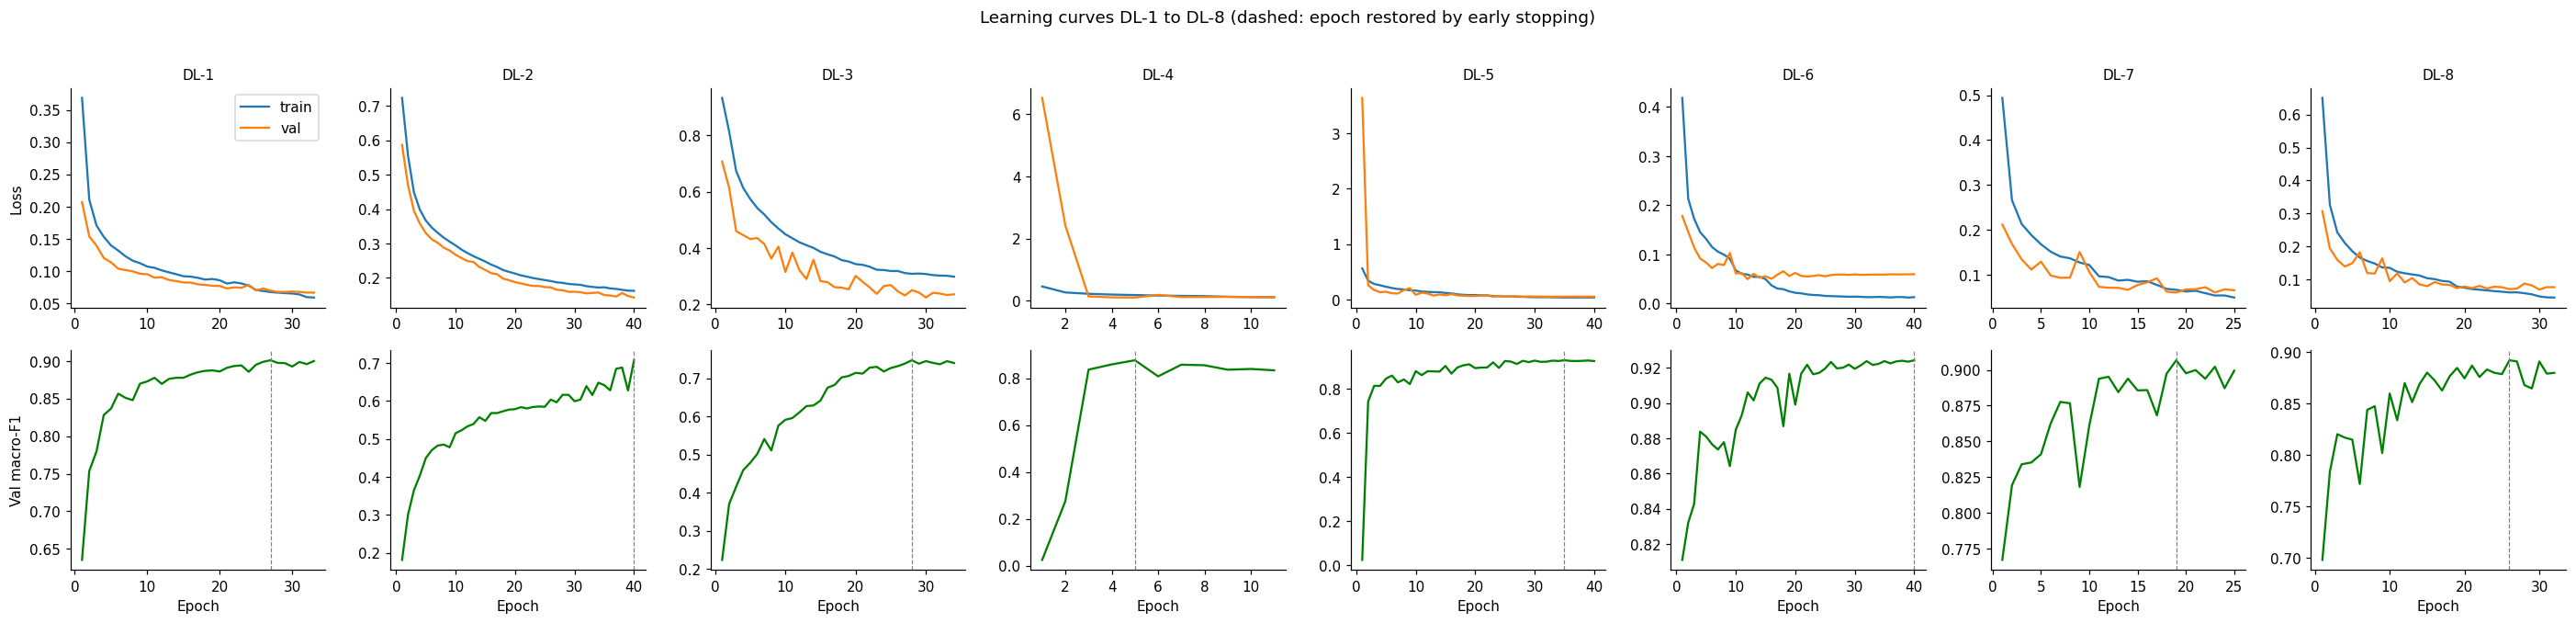

,epochs run,best epoch,min val loss epoch,final train loss,final val loss,val loss std (last 5)
DL-1,33.0,27.0,33.0,0.0590,0.0666,0.0007
DL-2,40.0,40.0,40.0,0.1621,0.1426,0.0044
DL-3,34.0,28.0,30.0,0.2985,0.2358,0.0058
DL-4,11.0,5.0,5.0,0.1110,0.1096,0.0040
DL-5,40.0,35.0,35.0,0.0417,0.0560,0.0006
DL-6,40.0,40.0,12.0,0.0131,0.0597,0.0001
DL-7,25.0,19.0,19.0,0.0492,0.0656,0.0038
DL-8,32.0,26.0,30.0,0.0448,0.0762,0.0061


In [27]:
dl_ids = list(DL_HISTORY)
fig, axes = plt.subplots(2, len(dl_ids), figsize=(3.2 * len(dl_ids), 6), squeeze=False)
for j, eid in enumerate(dl_ids):
    h = DL_HISTORY[eid]
    ep = np.arange(1, len(h["loss"]) + 1)
    axes[0, j].plot(ep, h["loss"], label="train")
    axes[0, j].plot(ep, h["val_loss"], label="val")
    axes[0, j].set_title(eid, fontsize=10)
    axes[1, j].plot(ep, h["val_macro_f1"], color="green")
    axes[1, j].axvline(int(np.argmax(h["val_macro_f1"])) + 1, ls="--", color="grey", lw=0.8)
    axes[1, j].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[1, 0].set_ylabel("Val macro-F1")
axes[0, 0].legend()
plt.suptitle("Learning curves DL-1 to DL-8 (dashed: epoch restored by early stopping)", y=1.02)
plt.tight_layout()
savefig("fig08_dl_learning_curves.png")
plt.show()

curve_summary = pd.DataFrame({eid: {"epochs run": len(h["loss"]), "best epoch": int(np.argmax(h["val_macro_f1"])) + 1,
                                    "min val loss epoch": int(np.argmin(h["val_loss"])) + 1,
                                    "final train loss": h["loss"][-1], "final val loss": h["val_loss"][-1],
                                    "val loss std (last 5)": float(np.std(h["val_loss"][-5:]))}
                              for eid, h in DL_HISTORY.items()}).T
display(curve_summary.round(4))

Reading the curves:

- **DL-2 is unfinished.** Both losses are still falling and F1 is still climbing at the last epoch: underfitting.
- **DL-3 levels off around 0.74.** Training and validation scores stay equal, so it also underfits; it just stopped improving.
- **DL-4 stalled.** F1 jumps to about 0.87 by epoch 5, then goes flat, and training stops at 11.
- **DL-5 is the healthy run.** After a first-epoch spike, both losses stay low and close, and F1 climbs steadily to 0.93.
- **DL-6 overfits in the loss.** Training loss keeps falling to about 0.01, while validation loss bottoms out around epoch 12.
  Its macro-F1 still kept improving until epoch 40, which is why I stop on macro-F1 and not on loss.
- **DL-7's loss lines stay much closer than DL-6's,** which is augmentation reducing overfitting.

In some panels validation loss sits below training loss. Dropout, augmentation and (from DL-3) class weights only apply
during training, so I compare how the gap changes, not which line is higher.

### 7.4 TensorBoard logs

TensorBoard's viewer doesn't run well inside Kaggle, so I read the event files directly and re-plot them. The full `logs/`
folder is zipped in Section 10 and opens locally with `tensorboard --logdir logs`.

Logged tags: ['epoch_learning_rate', 'epoch_loss', 'epoch_macro_f1']


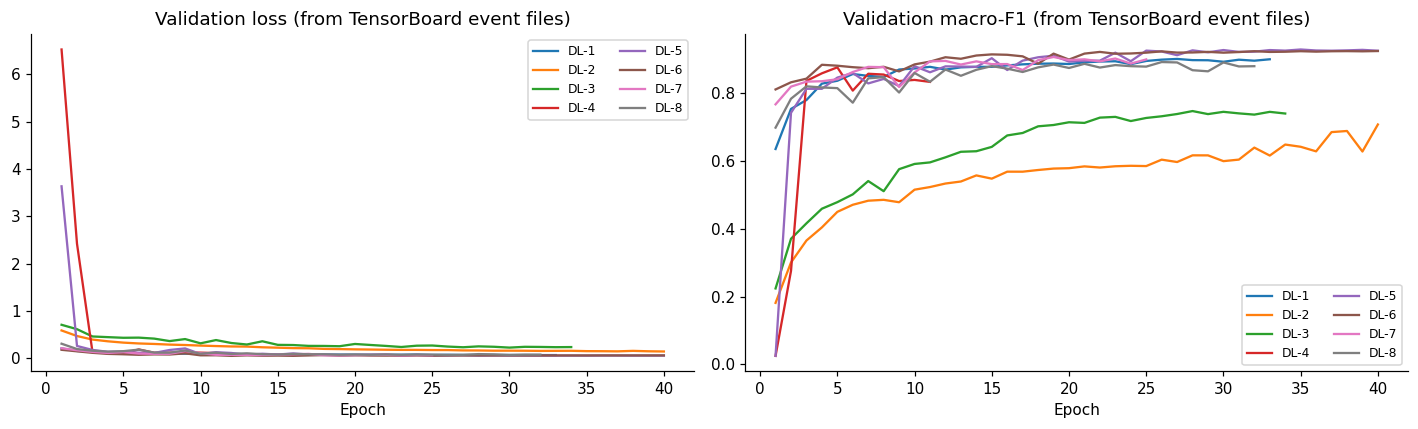

,TensorBoard best val F1,table val F1,difference
exp_id,,,
DL-1,0.9010,0.9010,0.0
DL-2,0.7076,0.7076,0.0
DL-3,0.7472,0.7472,0.0
DL-4,0.8762,0.8762,0.0
DL-5,0.9289,0.9289,0.0
DL-6,0.9243,0.9243,0.0
DL-7,0.9068,0.9068,0.0
DL-8,0.8918,0.8918,0.0


In [28]:
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

def read_tb_scalars(run_dir: str) -> pd.DataFrame:
    """Long table (split, tag, step, value) of the epoch scalars Keras' TensorBoard callback wrote."""
    rows = []
    for split in ["train", "validation"]:
        path = os.path.join(run_dir, split)
        if not os.path.isdir(path):
            continue
        ea = EventAccumulator(path, size_guidance={"tensors": 0, "scalars": 0})
        ea.Reload()
        for tag in ea.Tags().get("tensors", []):
            if tag.startswith("epoch_"):              # skip the model-config text summary
                rows += [(split, tag, e.step, float(tf.make_ndarray(e.tensor_proto))) for e in ea.Tensors(tag)]
        for tag in ea.Tags().get("scalars", []):
            rows += [(split, tag, e.step, e.value) for e in ea.Scalars(tag)]
    return pd.DataFrame(rows, columns=["split", "tag", "step", "value"])

tb = pd.concat([read_tb_scalars(os.path.join(DIRS["logs"], e)).assign(exp_id=e) for e in dl_ids], ignore_index=True)
print("Logged tags:", sorted(tb["tag"].unique()))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for eid, g in tb[(tb["tag"] == "epoch_loss") & (tb["split"] == "validation")].groupby("exp_id"):
    axes[0].plot(g["step"] + 1, g["value"], label=eid)
for eid, g in tb[tb["tag"] == "epoch_macro_f1"].groupby("exp_id"):
    axes[1].plot(g["step"] + 1, g["value"], label=eid)
axes[0].set_title("Validation loss (from TensorBoard event files)")
axes[1].set_title("Validation macro-F1 (from TensorBoard event files)")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
savefig("fig09_tensorboard_curves.png")
plt.show()

# Cross-check: the best logged macro-F1 per run should match the experiment table
check = (tb[tb["tag"] == "epoch_macro_f1"].groupby("exp_id")["value"].max().rename("TensorBoard best val F1")
         .to_frame().join(t["val_macro_f1"].rename("table val F1")))
check["difference"] = (check.iloc[:, 0] - check.iloc[:, 1]).abs()
display(check.round(4))

The best validation macro-F1 stored in each TensorBoard run matches the experiment table exactly (a
difference of 0.0 for all eight networks), so every number in the table traces back to a logged run.

## 8. Test results and error analysis

The best traditional model (ML-5) and the best network (DL-5), both chosen on validation macro-F1 only, are scored once on
the held-out test file. I also time predictions and measure model size.

In [29]:
dl_results_df = exp_table[exp_table["paradigm"] == "Deep Learning"]
BEST_DL_ID = dl_results_df.loc[dl_results_df["val_macro_f1"].idxmax(), "exp_id"]
best_dl_model = keras.models.load_model(DL_MODEL_PATHS[BEST_DL_ID])
print(f"Best traditional: {BEST_ML_ID} | Best deep learning: {BEST_DL_ID}")

def timed(fn, n_rep=3):
    fn()                                               # warm-up
    start = time.time()
    for _ in range(n_rep):
        out = fn()
    return out, (time.time() - start) / n_rep

def size_mb(obj=None, path=None):
    if path:
        return os.path.getsize(path) / 1e6
    tmp = os.path.join(DIRS["models"], "_tmp.joblib")
    joblib.dump(obj, tmp)
    s = os.path.getsize(tmp) / 1e6
    os.remove(tmp)
    return s

X_test_feats = feature_set(best_ml_record["feature_set"], "test")
test_ds = make_dataset(X_test, y_test, batch_size=1024)
proba_ml, t_ml = timed(lambda: best_ml_record["model"].predict_proba(X_test_feats))
proba_dl, t_dl = timed(lambda: best_dl_model.predict(test_ds, verbose=0))

test_summary = pd.DataFrame({
    f"{BEST_ML_ID} (traditional)": {**evaluate_predictions(y_test, proba_ml),
                                    "ms per 1,000 beats": 1e6 * t_ml / len(y_test),
                                    "model size (MB)": size_mb(obj=best_ml_record["model"])},
    f"{BEST_DL_ID} (deep learning)": {**evaluate_predictions(y_test, proba_dl),
                                      "ms per 1,000 beats": 1e6 * t_dl / len(y_test),
                                      "model size (MB)": size_mb(path=DL_MODEL_PATHS[BEST_DL_ID])}})
test_summary.to_csv(os.path.join(DIRS["results"], "test_summary.csv"))
display(test_summary.round(4))

for name, proba in [(BEST_ML_ID, proba_ml), (BEST_DL_ID, proba_dl)]:
    print(f"\n===== {name}: classification report (test) =====")
    print(classification_report(y_test, proba.argmax(1), target_names=SHORT, digits=4, zero_division=0))

Best traditional: ML-5 | Best deep learning: DL-5


,ML-5 (traditional),DL-5 (deep learning)
accuracy,0.9820,0.9855
balanced_acc,0.8631,0.9387
macro_f1,0.9014,0.9242
macro_auc,0.9933,0.9947
recall_N,0.9971,0.9918
recall_S,0.7068,0.8471
recall_V,0.9385,0.9634
recall_F,0.6975,0.9012
recall_Q,0.9757,0.9900
"ms per 1,000 beats",59.7146,14.6694



===== ML-5: classification report (test) =====
              precision    recall  f1-score   support

           N     0.9841    0.9971    0.9905     18118
           S     0.9269    0.7068    0.8020       556
           V     0.9631    0.9385    0.9507      1448
           F     0.8760    0.6975    0.7766       162
           Q     0.9987    0.9757    0.9871      1608

    accuracy                         0.9820     21892
   macro avg     0.9498    0.8631    0.9014     21892
weighted avg     0.9815    0.9820    0.9813     21892


===== DL-5: classification report (test) =====
              precision    recall  f1-score   support

           N     0.9938    0.9918    0.9928     18118
           S     0.8336    0.8471    0.8403       556
           V     0.9661    0.9634    0.9647      1448
           F     0.7766    0.9012    0.8343       162
           Q     0.9876    0.9900    0.9888      1608

    accuracy                         0.9855     21892
   macro avg     0.9115    0.9387  

DL-5 wins on the test set: macro-F1 0.924 vs 0.901, balanced accuracy 0.939 vs 0.863, and much better
recall on the rare classes (S 0.847 vs 0.707, F 0.901 vs 0.698). Accuracy (0.986 vs 0.982) barely separates them because
normal beats dominate.

DL-5 is also about 4× faster (14.7 vs 59.7 ms per 1,000 beats, before counting ML-5's feature extraction) and half the size
(2.1 vs 4.6 MB). The trade-off is precision: DL-5's S precision is 0.83, against 0.93 for ML-5.

### 8.1 Confusion matrices

Rows are true classes and columns are predictions. Each cell shows the share of its row (recall on the diagonal) and the raw
count, so the small classes stay readable.

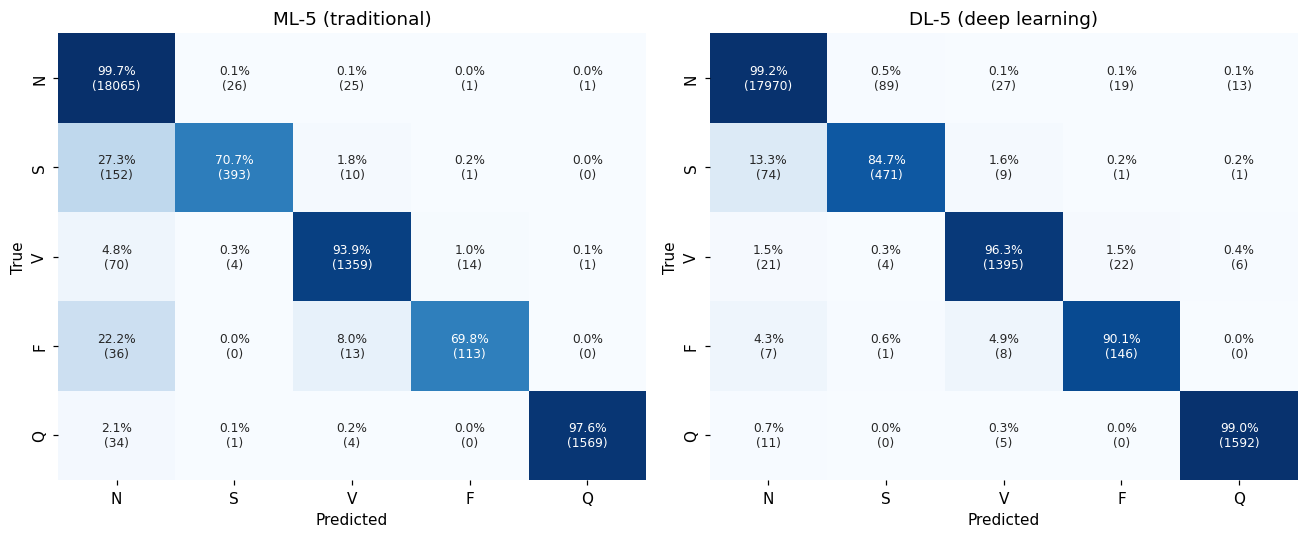

ML-5                                     DL-5                  \
  true predicted count share of true class true predicted count   
0    S         N   152               0.273    N         S    89   
1    V         N    70               0.048    S         N    74   
2    F         N    36               0.222    N         V    27   
3    Q         N    34               0.021    V         F    22   
4    N         S    26               0.001    V         N    21   
5    N         V    25               0.001    N         F    19   

                       
  share of true class  
0               0.005  
1               0.133  
2               0.001  
3               0.015  
4               0.015  
5               0.001

In [30]:
def plot_cm(ax, y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=range(N_CLASSES))
    cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    annot = np.array([[f"{cmn[i, j]:.1%}\n({cm[i, j]})" for j in range(N_CLASSES)] for i in range(N_CLASSES)])
    sns.heatmap(cmn, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=SHORT, yticklabels=SHORT, annot_kws={"fontsize": 8})
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)
    return cm

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
cm_ml = plot_cm(axes[0], y_test, proba_ml.argmax(1), f"{BEST_ML_ID} (traditional)")
cm_dl = plot_cm(axes[1], y_test, proba_dl.argmax(1), f"{BEST_DL_ID} (deep learning)")
plt.tight_layout()
savefig("fig10_confusion_matrices.png")
plt.show()

def top_confusions(cm, k=6):
    pairs = [(SHORT[i], SHORT[j], cm[i, j], cm[i, j] / max(cm[i].sum(), 1))
             for i in range(N_CLASSES) for j in range(N_CLASSES) if i != j]
    return pd.DataFrame(sorted(pairs, key=lambda p: -p[2])[:k], columns=["true", "predicted", "count", "share of true class"])

display(pd.concat({BEST_ML_ID: top_confusions(cm_ml), BEST_DL_ID: top_confusions(cm_dl)}, axis=1).round(3))

The two models make opposite mistakes. ML-5's biggest error is **missing** arrhythmias: it calls 152 S
beats (27%) and 36 F beats (22%) normal. DL-5's biggest error is **false alarms**: 89 normal beats called S, against only 74
S beats missed. For screening, a false alarm a clinician can dismiss is safer than a missed arrhythmia.

- **S → N** happens because S beats look normal; what defines them is timing, which one beat barely shows.
- **F and V errors** (for example 22 V beats called F by DL-5) make sense: a fusion beat is a blend of a normal and a
  ventricular beat.

### 8.2 ROC and precision-recall curves

One curve per class, one-vs-rest. I show both because ROC can look excellent for rare classes even when many alarms are false.

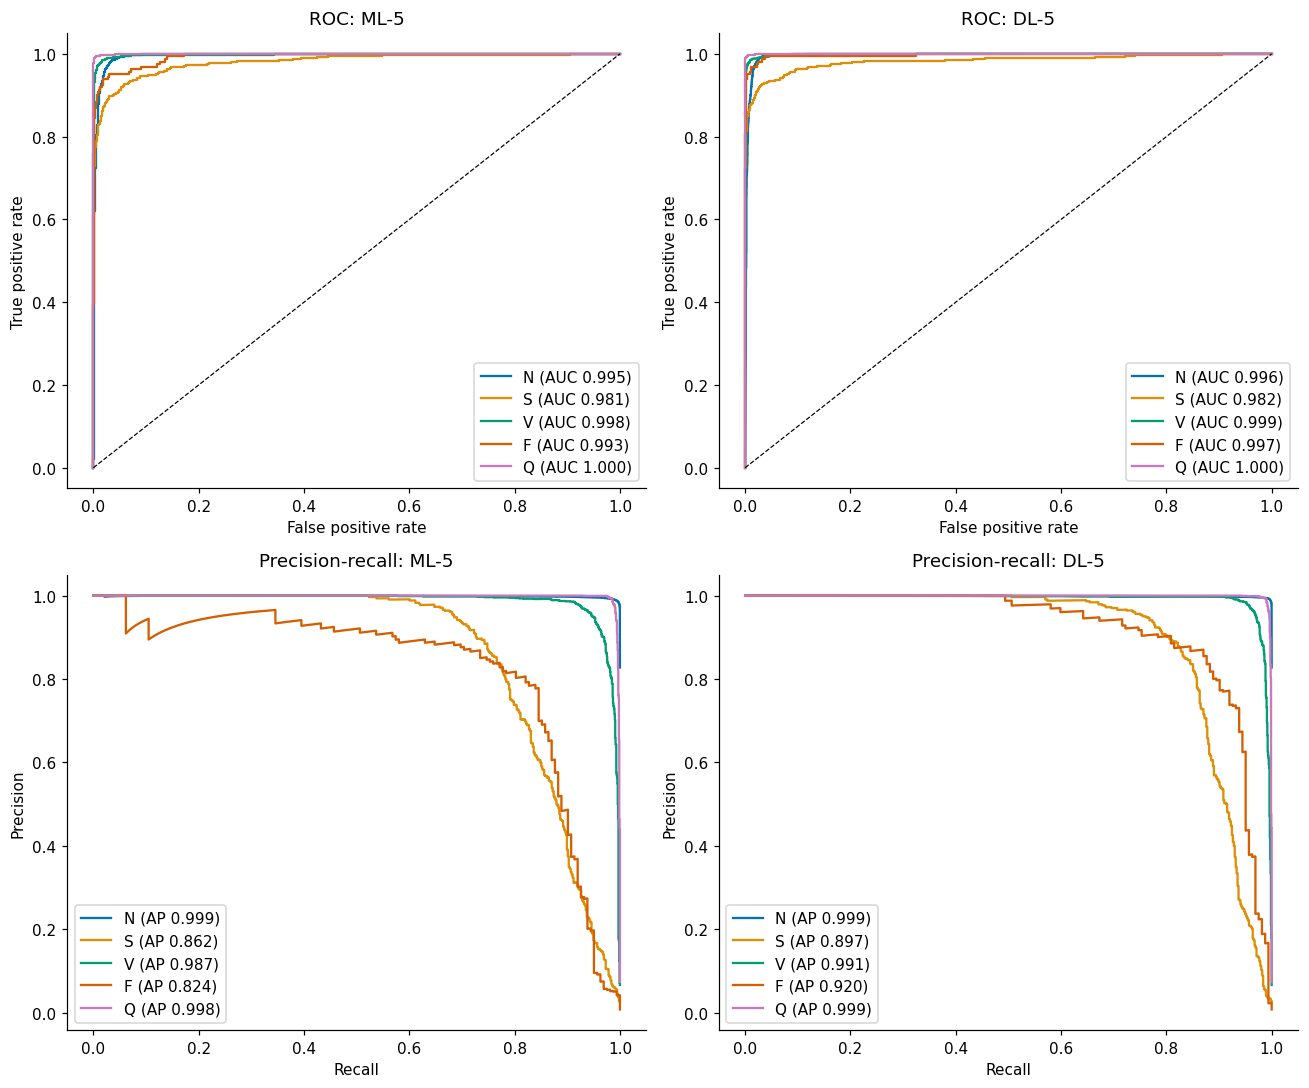

ROC-AUC         average precision        
model    DL-5    ML-5              DL-5    ML-5
class                                          
F      0.9967  0.9928            0.9202  0.8242
N      0.9961  0.9955            0.9988  0.9988
Q      0.9998  0.9998            0.9987  0.9981
S      0.9823  0.9807            0.8972  0.8617
V      0.9988  0.9976            0.9906  0.9867

In [31]:
y_test_bin = label_binarize(y_test, classes=range(N_CLASSES))
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
ap_rows = []
for col, (name, proba) in enumerate([(BEST_ML_ID, proba_ml), (BEST_DL_ID, proba_dl)]):
    for c in range(N_CLASSES):
        fpr, tpr, _ = roc_curve(y_test_bin[:, c], proba[:, c])
        roc_auc = auc(fpr, tpr)
        axes[0, col].plot(fpr, tpr, color=PALETTE[c], label=f"{SHORT[c]} (AUC {roc_auc:.3f})")
        prec, rec, _ = precision_recall_curve(y_test_bin[:, c], proba[:, c])
        ap = average_precision_score(y_test_bin[:, c], proba[:, c])
        axes[1, col].plot(rec, prec, color=PALETTE[c], label=f"{SHORT[c]} (AP {ap:.3f})")
        ap_rows.append({"model": name, "class": SHORT[c], "ROC-AUC": roc_auc, "average precision": ap})
    axes[0, col].plot([0, 1], [0, 1], "k--", lw=0.8)
    axes[0, col].set(xlabel="False positive rate", ylabel="True positive rate", title=f"ROC: {name}")
    axes[1, col].set(xlabel="Recall", ylabel="Precision", title=f"Precision-recall: {name}")
    axes[0, col].legend(loc="lower right")
    axes[1, col].legend(loc="lower left")
plt.tight_layout()
savefig("fig11_roc_pr_curves.png")
plt.show()
display(pd.DataFrame(ap_rows).pivot(index="class", columns="model").round(4))

ROC-AUC is above 0.98 for every class in both models, so ROC barely separates them (F: 0.997 vs 0.993).
Average precision does: F 0.920 vs 0.824, and S 0.897 vs 0.862. With about 21,700 non-F beats, a few hundred false alarms
hardly move the ROC curve but hurt precision a lot, so the PR curve is the honest view here. A screening tool could lower
the threshold for S and F to catch more of them, and the PR curve shows how much precision each extra point of recall costs.

### 8.3 What the errors look like

For DL-5's three most common confusions, I plot misclassified beats against the mean beat of the true class and of the
predicted class, then compare the model's confidence on correct and wrong predictions.

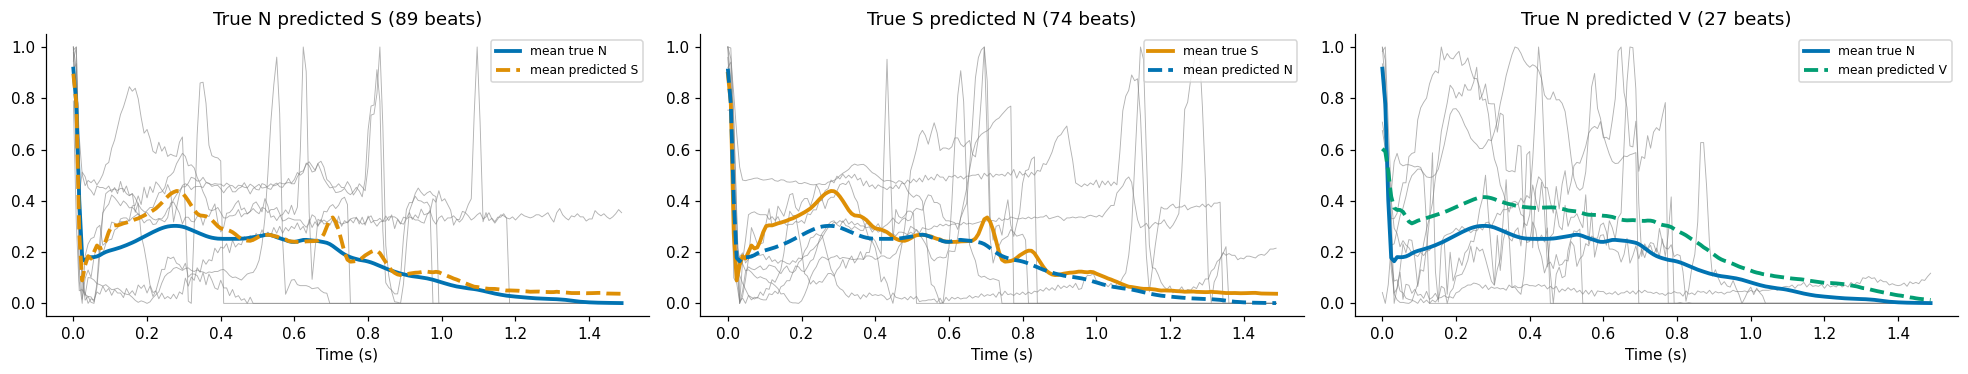

Median confidence: correct 1.000 | wrong 0.905
Flag beats with confidence < 0.6: 0.5% of beats flagged, containing 15.1% of all errors
Flag beats with confidence < 0.8: 1.5% of beats flagged, containing 37.7% of all errors
Flag beats with confidence < 0.9: 2.5% of beats flagged, containing 48.1% of all errors


In [32]:
pred_dl = proba_dl.argmax(1)
class_means = np.stack([X_train[y_train == c].mean(0) for c in range(N_CLASSES)])
pairs_dl = top_confusions(cm_dl, 3)
pairs_dl = pairs_dl[pairs_dl["count"] > 0]
if len(pairs_dl):
    fig, axes = plt.subplots(1, len(pairs_dl), figsize=(6 * len(pairs_dl), 3.5), squeeze=False)
    for ax, (_, row) in zip(axes[0], pairs_dl.iterrows()):
        ti, pi = SHORT.index(row["true"]), SHORT.index(row["predicted"])
        idx = np.where((y_test == ti) & (pred_dl == pi))[0]
        for i in idx[:8]:
            ax.plot(t_axis, X_test[i], color="grey", lw=0.6, alpha=0.6)
        ax.plot(t_axis, class_means[ti], color=PALETTE[ti], lw=2.5, label=f"mean true {row['true']}")
        ax.plot(t_axis, class_means[pi], color=PALETTE[pi], lw=2.5, ls="--", label=f"mean predicted {row['predicted']}")
        ax.set_title(f"True {row['true']} predicted {row['predicted']} ({int(row['count'])} beats)")
        ax.set_xlabel("Time (s)")
        ax.legend(fontsize=8)
    plt.tight_layout()
    savefig("fig12_error_examples.png")
    plt.show()

conf = proba_dl.max(1)
correct = pred_dl == y_test
print(f"Median confidence: correct {np.median(conf[correct]):.3f} | wrong {np.median(conf[~correct]):.3f}")
for thr in [0.6, 0.8, 0.9]:
    flagged = conf < thr
    print(f"Flag beats with confidence < {thr}: {flagged.mean():.1%} of beats flagged, "
          f"containing {(~correct & flagged).sum() / max((~correct).sum(), 1):.1%} of all errors")

The network is overconfident: its median confidence is 1.000 when right and still 0.905 when wrong. Even
so, confidence is useful for triage. Flagging the 2.5% least-confident beats (confidence below 0.9) would catch 48% of all
errors for a cardiologist to review. The scores would need calibrating before anyone trusted them clinically.

## 9. Inter-patient test

The Kaggle split is by heartbeat, so the test beats come from the same 47 people the models trained on. A real device always
meets new patients. Following de Chazal et al. (2004), this section rebuilds the beats from the raw PhysioNet recordings,
trains on 22 patients (DS1) and tests on 22 different patients (DS2).

During this run PhysioNet returned a server error (502), so the download failed and the section was skipped (see the output
below). I ran the same experiment separately in `ecg_inter_patient.ipynb`.

In [33]:
DS1 = [101, 106, 108, 109, 112, 114, 115, 116, 118, 119, 122, 124, 201, 203, 205, 207, 208, 209, 215, 220, 223, 230]
DS2 = [100, 103, 105, 111, 113, 117, 121, 123, 200, 202, 210, 212, 213, 214, 219, 221, 222, 228, 231, 232, 233, 234]
AAMI = {**{s: 0 for s in "NLRej"}, **{s: 1 for s in "AaJS"}, **{s: 2 for s in "VE"}, "F": 3, **{s: 4 for s in "/fQ"}}

def segment_record(sig_raw, r_peaks, symbols, fs_in=360, fs_out=FS, win_s=10):
    """Kachuee-style beat extraction from one recording -> (beats [n, 187], labels [n])."""
    sig = sps.resample_poly(sig_raw, fs_out, fs_in)
    r = np.round(np.asarray(r_peaks) * fs_out / fs_in).astype(int)
    keep = np.array([s in AAMI for s in symbols])
    beats, labels = [], []
    win = win_s * fs_out
    for start in range(0, len(sig) - win + 1, win):
        seg = sig[start:start + win]
        lo, hi = seg.min(), seg.max()
        if hi - lo < 1e-6:
            continue
        norm = (seg - lo) / (hi - lo)
        in_win = (r >= start) & (r < start + win)
        rr = np.diff(r[in_win])
        if len(rr) < 1:
            continue
        T = int(1.2 * np.median(rr))
        for k in np.where(in_win & keep)[0]:
            p = r[k] - start
            beat = norm[p:p + min(T, SEQ_LEN)]
            out = np.zeros(SEQ_LEN, dtype="float32")
            out[:len(beat)] = beat
            beats.append(out)
            labels.append(AAMI[symbols[k]])
    return np.array(beats, dtype="float32").reshape(-1, SEQ_LEN), np.array(labels, dtype=int)

def build_patient_set(records, db_dir):
    import wfdb
    Xs, ys, pids = [], [], []
    for rec in records:
        r = wfdb.rdrecord(os.path.join(db_dir, str(rec)))
        a = wfdb.rdann(os.path.join(db_dir, str(rec)), "atr")
        lead = r.sig_name.index("MLII") if "MLII" in r.sig_name else 0
        Xb, yb = segment_record(r.p_signal[:, lead], a.sample, a.symbol, fs_in=r.fs)
        Xs.append(Xb); ys.append(yb); pids += [rec] * len(yb)
    return np.vstack(Xs), np.concatenate(ys), np.array(pids)

INTER = {}
if RUN_INTER_PATIENT:
    try:
        try:
            import wfdb
        except ImportError:
            import subprocess, sys
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "wfdb"], check=True)
            import wfdb
        DB_DIR = os.path.join(OUT_DIR, "mitdb")
        ds1 = DS1 if not SMOKE_TEST else DS1[:2]
        ds2 = DS2 if not SMOKE_TEST else DS2[:2]
        if not all(os.path.exists(os.path.join(DB_DIR, f"{r}.dat")) for r in ds1 + ds2):
            wfdb.dl_database("mitdb", DB_DIR, records=[str(r) for r in ds1 + ds2])
        X_p1, y_p1, pid_p1 = build_patient_set(ds1, DB_DIR)
        X_p2, y_p2, _ = build_patient_set(ds2, DB_DIR)
        INTER = dict(X_p1=X_p1, y_p1=y_p1, pid_p1=pid_p1, X_p2=X_p2, y_p2=y_p2)
        display(pd.DataFrame({"DS1 (training patients)": np.bincount(y_p1, minlength=N_CLASSES),
                              "DS2 (unseen patients)": np.bincount(y_p2, minlength=N_CLASSES)}, index=SHORT).T)
    except Exception as e:
        print("Inter-patient data could not be prepared (is Internet enabled?):", repr(e))
else:
    print("RUN_INTER_PATIENT is False: skipping Section 9.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 6.4 MB/s eta 0:00:00
Generating record list for: 101
Generating record list for: 106
Generating record list for: 108
Generating record list for: 109
Generating record list for: 112
Generating record list for: 114
Generating record list for: 115
Generating record list for: 116
Generating record list for: 118
Generating record list for: 119
Generating record list for: 122
Generating record list for: 124
Generating record list for: 201
Generating record list for: 203
Generating record list for: 205
Generating record list for: 207
Generating record list for: 208
Generating record list for: 209
Generating record list for: 215
Generating record list for: 220
Generating record list for: 223
Generating record list for: 230
Generating record list for: 100
Generating record list for: 103
Generating record list for: 105
Generating record list for: 111
Generating record list for: 113
Generating record list for: 117
Generating record list f

In [34]:
if INTER:
    X_p1, y_p1, pid_p1, X_p2, y_p2 = (INTER[k] for k in ["X_p1", "y_p1", "pid_p1", "X_p2", "y_p2"])
    patients = np.unique(pid_p1)
    val_pat = np.random.default_rng(SEED).choice(patients, size=min(3, len(patients) - 1), replace=False)
    vm = np.isin(pid_p1, val_pat)                      # whole patients held out for early stopping

    # --- traditional: same configuration as the best ML experiment, refitted on DS1
    set_seeds()
    inter_ml = clone(best_ml_record["model"])
    inter_ml.fit(features_for(X_p1, best_ml_record["feature_set"]), y_p1)
    p = inter_ml.predict_proba(features_for(X_p2, best_ml_record["feature_set"]))
    proba_ml_p2 = np.zeros((len(y_p2), N_CLASSES))
    proba_ml_p2[:, inter_ml.classes_] = p

    # --- deep learning: same configuration as the best DL experiment, retrained on DS1
    cfg = DL_CONFIG[BEST_DL_ID]
    keras.backend.clear_session(); set_seeds()
    inter_dl = BUILDERS[cfg["arch"]](**cfg["arch_kwargs"])
    inter_dl.compile(optimizer=keras.optimizers.Adam(cfg["lr"]), loss="sparse_categorical_crossentropy")
    present = np.unique(y_p1[~vm])
    cw = compute_class_weight("balanced", classes=present, y=y_p1[~vm])
    cw_inter = {int(c): float(np.sqrt(w)) for c, w in zip(present, cw)} if cfg["class_weight"] is not None else None
    tr_ds = make_dataset(X_p1[~vm], y_p1[~vm], cfg["batch_size"], shuffle=True, use_augment=cfg["use_augment"])
    va_ds = make_dataset(X_p1[vm], y_p1[vm], 1024)
    inter_dl.fit(tr_ds, validation_data=va_ds, epochs=MAX_EPOCHS, class_weight=cw_inter, verbose=0,
                 callbacks=make_callbacks("INTER-DL", va_ds, y_p1[vm], csv=True))
    proba_dl_p2 = inter_dl.predict(make_dataset(X_p2, y_p2, 1024), verbose=0)

    inter_cmp = pd.DataFrame({
        f"{BEST_ML_ID} intra-patient (Kaggle test)": evaluate_predictions(y_test, proba_ml),
        f"{BEST_ML_ID} inter-patient (DS2)": evaluate_predictions(y_p2, proba_ml_p2),
        f"{BEST_DL_ID} intra-patient (Kaggle test)": evaluate_predictions(y_test, proba_dl),
        f"{BEST_DL_ID} inter-patient (DS2)": evaluate_predictions(y_p2, proba_dl_p2)})
    inter_cmp.to_csv(os.path.join(DIRS["results"], "inter_patient_comparison.csv"))
    display(inter_cmp.round(4))
    print("Note: class Q is nearly absent from DS1/DS2 (paced records excluded), so read per-class recall for N, S, V, F.")

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    plot_cm(axes[0], y_p2, proba_ml_p2.argmax(1), f"{BEST_ML_ID} on unseen patients (DS2)")
    plot_cm(axes[1], y_p2, proba_dl_p2.argmax(1), f"{BEST_DL_ID} on unseen patients (DS2)")
    plt.tight_layout()
    savefig("fig13_inter_patient_confusion.png")
    plt.show()

**Result (from `ecg_inter_patient.ipynb`).** On 22 unseen patients both models collapsed: macro-F1 fell from 0.901 to
0.315 for ML-5 and from 0.924 to 0.336 for DL-5. Accuracy still showed about 91% because S recall dropped to almost zero.
Most of the headline score was patient recognition, which matches the shortcut risk I flagged in Section 2.4. DL-5 held up
much better on V beats (recall 0.81 vs 0.51), which are defined by shape rather than timing.

## 10. Saving

These go to the Google Drive folder, together with the zipped raw dataset:

- `models/best_traditional_model.joblib`: the fitted ML-5 pipeline and the feature set it expects
- `models/best_dl_model.keras`: DL-5; `models/DL-*.keras` hold every run
- `results/*.csv`: experiment table, deltas, search results and test summary
- `figures/*.png`: every figure for the report
- `tensorboard_logs.zip`: all TensorBoard event files and CSV logs

In [35]:
joblib.dump({"pipeline": best_ml_record["model"], "feature_set": best_ml_record["feature_set"],
             "feature_names": FEATURE_NAMES[best_ml_record["feature_set"]], "classes": SHORT,
             "usage": "X = features_for(beats, feature_set); pipeline.predict(X)"},
            os.path.join(DIRS["models"], "best_traditional_model.joblib"))
shutil.copy(DL_MODEL_PATHS[BEST_DL_ID], os.path.join(DIRS["models"], "best_dl_model.keras"))
shutil.make_archive(os.path.join(OUT_DIR, "tensorboard_logs"), "zip", DIRS["logs"])

with open(os.path.join(DIRS["results"], "run_info.json"), "w") as fh:
    json.dump({"best_traditional": BEST_ML_ID, "best_deep_learning": BEST_DL_ID, "seed": SEED, "smoke_test": SMOKE_TEST,
               "tensorflow": tf.__version__, "mixed_precision": mixed_precision.global_policy().name,
               "train_rows": int(len(y_train)), "val_rows": int(len(y_val)), "test_rows": int(len(y_test))}, fh, indent=2)

for root, _, files in os.walk(OUT_DIR):
    if any(skip in root for skip in ["logs", "mitdb"]):
        continue
    for fn in sorted(files):
        path = os.path.join(root, fn)
        print(f"{os.path.relpath(path, OUT_DIR):55s} {os.path.getsize(path) / 1e6:8.2f} MB")

__notebook__.ipynb                                          1.83 MB
tensorboard_logs.zip                                        0.05 MB
figures/fig01_class_distribution.png                        0.03 MB
figures/fig02_example_beats.png                             0.23 MB
figures/fig03_mean_beats.png                                0.19 MB
figures/fig04_effective_length.png                          0.03 MB
figures/fig05_feature_importance.png                        0.07 MB
figures/fig06_learning_curve_best_ml.png                    0.06 MB
figures/fig07_experiment_comparison.png                     0.05 MB
figures/fig08_dl_learning_curves.png                        0.29 MB
figures/fig09_tensorboard_curves.png                        0.11 MB
figures/fig10_confusion_matrices.png                        0.10 MB
figures/fig11_roc_pr_curves.png                             0.17 MB
figures/fig12_error_examples.png                            0.31 MB
results/ML-5_search_results.csv                 

## 11. Conclusions

- **Deep learning won on the Kaggle test set.** DL-5 reached 0.924 macro-F1 against 0.901 for ML-5, with much better S and F
  recall, a quarter of the prediction time and half the size.
- **The most informative experiments:** features and boosting on the traditional side, and the learning rate on the deep
  side. DL-4 and DL-5 are the same network, so their 0.053 gap showed my CNNs were limited by optimisation, not capacity.
- **Bias and variance:** boosting overfits (a 0.11 gap on its learning curve), the small CNNs underfit, and augmentation
  traded a little accuracy for a smaller gap.
- **Errors:** S beats get confused with normal beats because they differ in timing, not shape; F beats are a blend of N and V.
- **The big limitation:** on unseen patients both models dropped to about 0.3 macro-F1, so this benchmark mostly measures
  patient recognition.
- **Next steps:** RR-interval features from neighbouring beats (for S), more and more diverse patients including African data,
  oversampling or targeted augmentation for F, multi-lead input, and patient-specific fine-tuning.